# NB03A — Extensión complementaria de sentimiento

**Estatus:** complementario  
**Objetivo:** construir features de sentimiento diario y metadata operativa para el híbrido, preservando alineación causal con el benchmark principal.  
**Inputs mínimos:** consultas/cachés de titulares, respaldo EIA, calendario de trading y `data/processed/wti_volatilidad_MODEL_BASE.csv`.  
**Outputs principales:** `data/sentiment/wti_sentiment_finbert.csv`, figuras diagnósticas y actualización de `nb03`.  
**Config / gobernanza:** este notebook actualiza `nb03` cuando se ejecuta en el pipeline activo; el contrato central del benchmark sigue en NB02 CPU.  
**No inferir de este notebook:** la extensión de sentimiento no redefine el benchmark canónico ni prueba por sí sola superioridad del híbrido.

**Contrato de config (runtime Colab):** NB03A usa `BASE_PATH/config_estudio_FINAL.json` como ruta real de runtime y solo actualiza `nb03` cuando la extensión está aprobada. El archivo del repo `config/config_estudio_FINAL.json` es un espejo sincronizado después de la corrida.  
**Orden oficial:** `NB01 -> NB03A (si aprobado) -> NB03B (si aprobado) -> NB02 CPU -> NB02 GPU opcional`. NB03A es una rama opcional previa al cierre canónico CPU.  
**Opt-in explícito:** `WRITE_NB03 = False` por defecto; si queda en `False`, el notebook puede exportar artefactos pero no modifica el config.


## 0. Instalación y Configuración

In [1]:
# gdeltdoc: cliente oficial de GDELT Project
# transformers: FinBERT (ProsusAI/finbert)
# torch: backend para inferencia FinBERT
# sentencepiece: tokenizador BERT

# Fijar pandas a versión compatible con Colab antes de instalar gdeltdoc
!pip install "pandas==2.2.2" gdeltdoc transformers torch sentencepiece -q

# Verificar versiones
import pandas as pd
import transformers
print(f"pandas      : {pd.__version__}   (requerido: <3.0.0)")
print(f"transformers: {transformers.__version__}")

# Guard de versión
assert pd.__version__.startswith('2.'), \
    f"pandas {pd.__version__} incompatible — REINICIA EL RUNTIME (Entorno de ejecución > Reiniciar sesión) y vuelve a ejecutar."
print("Dependencias OK")


pandas      : 2.2.2   (requerido: <3.0.0)
transformers: 5.0.0
Dependencias OK


In [2]:
import sys, os, json, random, re, time, warnings, pickle
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy  as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns

from collections import Counter

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.6f}'.format)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)      # Python — para shuffle si lo hay
np.random.seed(RANDOM_SEED)   # NumPy — para operaciones de muestreo
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)  # orden interno Python
import torch
torch.manual_seed(RANDOM_SEED)

print('Imports OK')
print(f'Python  : {sys.version.split()[0]}')
print(f'Pandas  : {pd.__version__}')
print(f'NumPy   : {np.__version__}')
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
    torch.backends.cudnn.deterministic = True   # operaciones deterministicas
    torch.backends.cudnn.benchmark = False       # desactiva autotuner
_device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"RANDOM_SEED={RANDOM_SEED} | torch={torch.__version__} | "
      f"Python={sys.version.split()[0]} | device={_device}")


Imports OK
Python  : 3.12.13
Pandas  : 2.2.2
NumPy   : 2.0.2
RANDOM_SEED=42 | torch=2.10.0+cu128 | Python=3.12.13 | device=cuda


In [3]:
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive', force_remount=False)
    BASE_PATH = "/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos"
    NB03_PATH = f"{BASE_PATH}/NB03_FinBERT"
    FIG_PATH  = f"{NB03_PATH}/Fig_NB03"
else:
    # Entorno local: rutas relativas a la raíz del proyecto
    BASE_PATH = str(Path(__file__).resolve().parents[1]) if '__file__' in dir() else '.'
    NB03_PATH = os.path.join(BASE_PATH, "NB03_FinBERT")
    FIG_PATH  = os.path.join(NB03_PATH, "Fig_NB03")

# Crear directorios (Colab y local)
for _dir in [NB03_PATH, FIG_PATH]:
    os.makedirs(_dir, exist_ok=True)

CONFIG_RUNTIME_PATH = f"{BASE_PATH}/config_estudio_FINAL.json"
CONFIG_REPO_MIRROR = "config/config_estudio_FINAL.json"
CONFIG_PATH  = CONFIG_RUNTIME_PATH
WRITE_NB03 = False   # True solo si la extensión de sentimiento fue aprobada para persistirse en config

CSV_MODEL_BASE = f"{BASE_PATH}/NB01_EDA/wti_volatilidad_MODEL_BASE.csv"  # backbone canonico downstream (NB01 -> NB02 -> NB03)
OUTPUT_SENT  = f"{NB03_PATH}/wti_sentiment_finbert.csv"
CACHE_RAW    = f"{NB03_PATH}/wti_gdelt_raw_2017_2026.csv"
FINBERT_CACHE= f"{NB03_PATH}/finbert_scores_cache.pkl"

# Validación de rutas críticas
assert os.path.exists(CONFIG_PATH), (
    f"CONFIG no encontrado: {CONFIG_PATH}\n  → Ejecutar NB01 primero.")
assert os.path.exists(CSV_MODEL_BASE), f"No encontrado: {CSV_MODEL_BASE}. Regenerar NB01 primero."
print(" Rutas validadas")
print(f" Config runtime : {CONFIG_RUNTIME_PATH}")
print(f" Espejo repo    : {CONFIG_REPO_MIRROR}")
print(f" WRITE_NB03     : {WRITE_NB03}")
print(" NB03A es una rama opcional previa al cierre canónico de NB02 CPU.")

# Cargar config NB01
with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
    config = json.load(f)

START_DATE = config['fechas']['start_date']   # 2000-01-01
END_DATE   = config['fechas']['end_date']     # 2026-02-28
TRAIN_END  = config['fechas']['train_end']    # 2018-12-31
VAL_START  = config['fechas']['val_start']    # 2019-01-02
VAL_END    = config['fechas']['val_end']      # 2020-12-31
TEST_START = config['fechas']['test_start']   # 2021-01-02

print(f'BASE_PATH : {BASE_PATH}')
print(f'NB03_PATH : {NB03_PATH}')
print(f'Período   : {START_DATE} → {END_DATE}')
print('Config cargado')

Mounted at /content/drive
 Rutas validadas
 Config runtime : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
 Espejo repo    : config/config_estudio_FINAL.json
 WRITE_NB03     : False
 NB03A es una rama opcional previa al cierre canónico de NB02 CPU.
BASE_PATH : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos
NB03_PATH : /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT
Período   : 2000-01-01 → 2026-02-28
Config cargado


In [4]:
# FIGURE_UTILS — Celda universal de importación v2.3
# Proyecto WTI Tesis | Una sola copia en cada notebook

# ── Rutas candidatas (Colab → local) ──
for _p in [
    '/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/utils',
    os.path.abspath('./utils'),
    os.path.abspath('../utils'),
]:
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

try:
    from figure_utils import (
        fig_size, save_fig, apply_thesis_style, add_top_legend,
        # Splits y clases
        SPLIT_COLORS, COLOR_NORMAL, COLOR_EXTREMO,
        # Series principales
        COLOR_PRECIO, COLOR_VOL, COLOR_CLEAN, COLOR_VAR, COLOR_DYN,
        # Percentiles y modelos
        COLORS_P, COLORES_MODELOS, COLORES_B,
        # NB03A y NB03B
        COLORS_SENT, COLORS_SIGNALS,
    )
    mpl.rcParams.update(mpl.rcParamsDefault)
    apply_thesis_style('A4')
    print("[OK] figure_utils v2.3 cargado desde utils/")

except Exception as e:
    warnings.warn(
        "[figure_utils] utils/ no disponible o falló import — activando fallback inline.\n"
        f"  Detalle: {type(e).__name__}: {e}",
        UserWarning, stacklevel=2
    )

    # ── Fallback inline (espejo exacto de v2.3) ─
    def fig_size(layout='full', fmt='A4', aspect=0.618):
        tw, th = (6.11, 9.73) if fmt == 'A4' else (6.34, 9.04)
        opts = {
            'full': (tw, tw*aspect), 'half': (tw/2, (tw/2)*aspect),
            'wide': (tw, tw*0.45),   '2x1':  (tw, tw*0.50),
            '2x2':  (tw, tw*0.75),   '3x1':  (tw, tw*0.38),
            'square': (tw, tw),      'tall': (tw, min(tw*1.40, th*0.85)),
            'page': (tw, th*0.90),
            'nb03_ts':   (tw, min(tw*1.45, th*0.92)),
            'nb03_dist': (tw, tw*0.62),
            'nb03_corr': (tw, tw*0.95),
        }
        result = opts.get(layout)
        if result is None:
            warnings.warn(f"Layout '{layout}' no reconocido. Usando 'full'.", UserWarning)
            result = opts['full']
        return tuple(round(x, 4) for x in result)

    def save_fig(fig_or_none=None, filename='', output_path='.', dpi=300,
                 fmt='png', fmt_page='A4', warn=True, **kwargs):
        if not filename or not filename.strip():
            raise ValueError("filename no puede estar vacío en save_fig().")
        fig = fig_or_none if fig_or_none is not None else plt.gcf()
        os.makedirs(output_path, exist_ok=True)
        path = os.path.join(output_path,
                            f"{filename.replace(' ','_').replace('/','_')}.{fmt}")
        fig.savefig(path, dpi=dpi, bbox_inches='tight', pad_inches=0.04,
                    facecolor='white', edgecolor='none', **kwargs)
        w, h = fig.get_size_inches()
        print(f"  [OK] {path}  [{w:.1f}\"×{h:.1f}\" @ {dpi}dpi]")
        return path

    def add_top_legend(handles, labels=None, ax=None, fig=None,
                       ncol=4, y=0.98, fontsize=8.5, frameon=True):
        if fig is None and ax is None:
            raise ValueError("Debes pasar ax o fig.")
        kw = dict(ncol=ncol, fontsize=fontsize, frameon=frameon,
                  columnspacing=1.2, handletextpad=0.6)
        if fig is not None:
            return fig.legend(handles=handles, labels=labels,
                              loc='upper center', bbox_to_anchor=(0.5, y), **kw)
        return ax.legend(handles=handles, labels=labels,
                         loc='lower center', bbox_to_anchor=(0.5, 1.02), **kw)

    # ── Paletas canónicas v2.3
    # Splits y clases
    SPLIT_COLORS  = {'train': '#2166ac', 'validation': '#f4a582',
                     'val': '#f4a582',   'test': '#d6604d'}
    COLOR_NORMAL  = '#2166ac'
    COLOR_EXTREMO = '#d73027'
    # Series principales
    COLOR_PRECIO  = '#253494'
    COLOR_VOL     = '#2c7bb6'
    COLOR_CLEAN   = '#4575b4'
    COLOR_VAR     = '#74add1'
    COLOR_DYN     = '#f4a582'
    # Percentiles
    COLORS_P      = {90: '#fdae61', 95: '#d73027', 99: '#7b2d8b'}
    # Modelos benchmark NB02
    COLORES_MODELOS = {
        'GARCH':             '#7b2d8b',
        'LSTM-Simple-Uni':   '#74add1',
        'LSTM-Simple-Multi': '#4575b4',
        'BiDir-LSTM-Uni':    '#d73027',
        'BiDir-LSTM-Multi':  '#f46d43',
        'Hybrid-Sent':       '#fdae61',
        'Hybrid-MktSignals': '#fee090',
        'Baseline-B1':       '#aaaaaa',
        'Baseline-B5':       '#555555',
    }
    # Baselines NB01
    COLORES_B     = ['#aaaaaa', '#2166ac', '#f4a582',
                     '#4575b4', '#d6604d', '#7b2d8b']
    # Sentimiento NB03A
    COLORS_SENT   = {'positive': '#1a9641', 'negative': '#d7191c', 'neutral': '#b0b0b0'}
    # Señales mercado NB03B
    COLORS_SIGNALS = {'OVX': '#d73027', 'VIX': '#4575b4',
                      'DXY': '#1a9641',  'EIA': '#7b2d8b'}

    # ── Estilo IEEE fallback
    mpl.rcParams.update(mpl.rcParamsDefault)
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except Exception:
        pass
    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Computer Modern', 'DejaVu Serif'],
        'font.size': 10,
        'axes.titlesize': 11, 'axes.titleweight': 'bold',
        'axes.titlelocation': 'center', 'axes.titlepad': 10,
        'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
        'xtick.major.pad': 3.5, 'ytick.major.pad': 3.5,
        'legend.fontsize': 9, 'legend.frameon': True,
        'legend.framealpha': 0.85, 'legend.edgecolor': 'gray',
        'figure.dpi': 150, 'savefig.dpi': 300,
        'figure.facecolor': 'white', 'axes.facecolor': 'white',
        'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': ':',
        'axes.edgecolor': 'black', 'axes.linewidth': 0.8,
        'lines.linewidth': 1.5, 'lines.markersize': 4,
    })
    print("[OK] figure_utils fallback inline activo (v2.3)")

# ── NOTA: NO definir colores adicionales después de este bloque ───
# Todas las variables canónicas ya están importadas o definidas en el fallback.
# Variables legacy eliminadas:
#   split_colors, COLORES_SPLIT, colores, COLOR_NORMAL_NB01, COLOR_EXTREMO_NB01
#   COLOR_CLEAN='#27ae60', COLOR_VAR='#8B2020', COLOR_DYN='darkorange'

[IEEE v2.3] Estilo aplicado — A4: 6.11"×9.73" (15.5×24.7 cm)
  Layouts (figsize):
    fig_size('full     ') -> (6.11, 3.78)"
    fig_size('half     ') -> (3.06, 1.89)"
    fig_size('wide     ') -> (6.11, 2.75)"
    fig_size('2x1      ') -> (6.11, 3.06)"
    fig_size('2x2      ') -> (6.11, 4.58)"
    fig_size('3x1      ') -> (6.11, 2.32)"
    fig_size('tall     ') -> (6.11, 8.27)"
    fig_size('page     ') -> (6.11, 8.76)"
    fig_size('nb03_ts  ') -> (6.11, 8.86)"
    fig_size('nb03_dist') -> (6.11, 3.79)"
    fig_size('nb03_corr') -> (6.11, 5.80)"
[OK] figure_utils v2.3 cargado desde utils/


# Parámetros clave

- **Objetivo del notebook:** construir y validar features diarias de sentimiento para el híbrido, preservando alineación causal con el benchmark de NB02.
- **Fuente(s) principal(es):** titulares GDELT, respaldo EIA y calendario de trading derivado de `data/processed/wti_volatilidad_MODEL_BASE.csv`.
- **Configuración metodológica fija:** la cobertura real de noticias comienza en 2017, el alineamiento se hace sobre días de trading y el modelo downstream solo debe consumir columnas `_lag1`.
- **Supuestos/restricciones relevantes:** la imputación es causal dentro del período con cobertura real y el sentimiento previo a 2017 se conserva como `NaN` para no fabricar señal fuera de soporte.
- **Artefactos de salida principales:** `data/sentiment/wti_sentiment_finbert.csv`, figuras diagnósticas y actualización de `nb03`.
- **Notas de reproducibilidad:** este notebook aporta una extensión complementaria; no debe usarse para inferir el canon del benchmark ni para sobredimensionar el valor predictivo de la señal.

In [5]:
from gdeltdoc import GdeltDoc, Filters

# Términos de búsqueda — cubren petróleo crudo WTI y mercados de energía
# Se usan términos en inglés porque GDELT indexa mayoría de medios en inglés
# NOTA: cada término = 1 request por bloque trimestral (~36 bloques 2017-2026)
SEARCH_TERMS = [
    'WTI crude oil',
    'crude oil price',
    'oil price volatility',
    'OPEC crude oil',
    'oil market',
]

# Dominios de noticias financieras de alta calidad
# (reducen ruido frente a blogs/tabloides)
DOMAINS = [
    'reuters.com',
    'bloomberg.com',
    'wsj.com',
    'ft.com',
    'cnbc.com',
    'marketwatch.com',
    'oilprice.com',
]

print('Términos de búsqueda configurados:')
for t in SEARCH_TERMS:
    print(f'  - {t}')
print(f'\nDominios preferidos: {len(DOMAINS)}')


Términos de búsqueda configurados:
  - WTI crude oil
  - crude oil price
  - oil price volatility
  - OPEC crude oil
  - oil market

Dominios preferidos: 7


In [6]:
# GDELT 2.0 tiene cobertura confiable desde 2017-01-01.
# Fechas anteriores se ajustan automáticamente.
# Rate limit manejado con backoff exponencial.

API_MIN_DATE    = pd.Timestamp("2017-01-01")
RATE_LIMIT_KEYS = ("ratelimit", "please limit requests", "too many requests")

def _quarter_blocks(start: str, end: str) -> list:
    """Genera bloques trimestrales en formato YYYY-MM-DD."""
    t0 = pd.Timestamp(start).normalize()
    t1 = pd.Timestamp(end).normalize()

    if t0 < API_MIN_DATE:
        print(f"⚠  START_DATE {t0.date()} fuera de rango GDELT 2.0. "
              f"Ajustado a {API_MIN_DATE.date()}.")
        t0 = API_MIN_DATE

    today = pd.Timestamp(datetime.now(timezone.utc).date())
    if t1 > today:
        t1 = today

    if t0 >= t1:
        raise ValueError(f"Rango inválido: {t0.date()} → {t1.date()}")

    blocks, cur = [], t0
    while cur < t1:
        nxt = min(cur + pd.DateOffset(months=3), t1)
        blocks.append((cur.strftime("%Y-%m-%d"), nxt.strftime("%Y-%m-%d")))
        cur = nxt
    return blocks

def _is_rate_limit(exc: Exception) -> bool:
    msg = repr(exc).lower()
    return any(k in msg for k in RATE_LIMIT_KEYS)

def _search_with_retry(gd, term, t_start, t_end,
                       max_retries=3, base_sleep=10.0):
    """Ejecuta una búsqueda GDELT con reintentos ante rate limit."""
    for attempt in range(max_retries + 1):
        try:
            f = Filters(keyword=term, start_date=t_start, end_date=t_end)
            return gd.article_search(f)
        except Exception as exc:
            if not _is_rate_limit(exc) or attempt == max_retries:
                print(f"  Error [{t_start}] '{term}': {repr(exc)}")
                return None
            wait = base_sleep * (2 ** attempt)
            print(f"  Rate limit [{t_start}] '{term}' → "
                  f"reintento {attempt+1}/{max_retries} en {wait:.0f}s")
            time.sleep(wait)
    return None

def download_gdelt(cache_path, search_terms, start_date, end_date,
                   sleep_s=6.0, max_retries=3,
                   base_sleep=10.0, block_pause=8.0):
    """
    Descarga artículos GDELT por bloques trimestrales con cache local.

    Parámetros
    -
    cache_path   : str   — ruta del CSV de cache
    search_terms : list  — términos de búsqueda
    start_date   : str   — fecha inicio (se ajusta a 2017-01-01 si es anterior)
    end_date     : str   — fecha fin
    sleep_s      : float — pausa entre requests (mín 5s por política GDELT)
    max_retries  : int   — reintentos ante rate limit
    base_sleep   : float — base del backoff exponencial (segundos)
    block_pause  : float — pausa adicional entre bloques trimestrales
    """
    #  Cargar cache si existe
    if os.path.exists(cache_path):
        print(f"Cache encontrado: {cache_path}")
        df = pd.read_csv(cache_path, parse_dates=["seendate"])
        print(f"  {len(df):,} artículos cargados")
        return df

    #  Descarga
    print("Iniciando descarga GDELT...")
    gd      = GdeltDoc()
    chunks  = []
    blocks  = _quarter_blocks(start_date, end_date)
    n       = len(blocks)
    terms   = list(search_terms)

    print(f"Bloques trimestrales: {n} | Términos: {len(terms)}")
    print(f"Período efectivo: {blocks[0][0]} → {blocks[-1][1]}\n")

    for i, (t0, t1) in enumerate(blocks, 1):
        block = []
        for term in terms:
            result = _search_with_retry(gd, term, t0, t1,
                                        max_retries, base_sleep)
            if result is not None and not result.empty:
                block.append(result)
            time.sleep(max(sleep_s, 5.0))   # nunca menos de 5s

        if block:
            chunks.append(pd.concat(block, ignore_index=True))

        if i % 5 == 0 or i == n:
            acc = sum(len(c) for c in chunks)
            print(f"  [{i:3d}/{n}] {t0} | acumulado: {acc:,} artículos")

        if block_pause > 0:
            time.sleep(block_pause)

    #  Consolidar
    if not chunks:
        print(" Sin artículos — verificar conexión y términos de búsqueda")
        return pd.DataFrame()

    df = pd.concat(chunks, ignore_index=True)

    # Deduplicar entre términos del mismo bloque
    if {"url", "title"}.issubset(df.columns):
        before = len(df)
        df = df.drop_duplicates(subset=["url", "title"], keep="first")
        print(f"Deduplicación: {before:,} → {len(df):,} artículos únicos")

    # Normalizar fecha
    if "seendate" in df.columns:
        df["seendate"] = pd.to_datetime(df["seendate"],
                                         errors="coerce", utc=True)

    df.to_csv(cache_path, index=False)
    print(f"Cache guardado: {cache_path}")
    print(f"Total: {len(df):,} artículos | "
          f"Período: {df['seendate'].min()} → {df['seendate'].max()}")
    return df

#  Ejecución
df_raw = download_gdelt(
    cache_path   = CACHE_RAW,
    search_terms = SEARCH_TERMS,   # definidos en Cell 1.1
    start_date   = START_DATE,     # del config — se ajusta a 2017-01-01
    end_date     = END_DATE,
    sleep_s      = 6.0,            # política GDELT: 1 request cada 5s
    max_retries  = 3,
    base_sleep   = 10.0,
    block_pause  = 8.0,
)

if not df_raw.empty:
    print(f"\nColumnas: {list(df_raw.columns)}")
    display(df_raw.head(3))


Cache encontrado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/wti_gdelt_raw_2017_2026.csv
  36,610 artículos cargados

Columnas: ['url', 'url_mobile', 'title', 'seendate', 'socialimage', 'domain', 'language', 'sourcecountry']


,url,url_mobile,title,seendate,socialimage,domain,language,sourcecountry
0,http://www.investegate.co.uk/etfs-commodity-se...,NaN,FE Investegate,2017-03-02 17:00:00+00:00,NaN,investegate.co.uk,English,United Kingdom
1,http://www.pressreleasepoint.com/proshares-lau...,NaN,ProShares Launches First and Only 3x and,2017-03-27 18:00:00+00:00,NaN,pressreleasepoint.com,English,United States
2,http://www.investegate.co.uk/etfs-commodity-se...,NaN,FE Investegate,2017-03-08 15:00:00+00:00,NaN,investegate.co.uk,English,United Kingdom


In [7]:
# NOTA: Si cambiaste los SEARCH_TERMS o quieres actualizar el período,
# elimina el cache manualmente antes de ejecutar:
#   import os; os.remove(CACHE_RAW)  # o bórralo desde el panel de archivos de Drive

if Path(CACHE_RAW).exists():
    # Cargar con parse_dates para mantener tipo consistente
    df_raw = pd.read_csv(CACHE_RAW, parse_dates=['seendate'])
    if df_raw.empty:
        print('[WARN] Cache GDELT vacío — se recomienda eliminar el cache y volver a ejecutar')
    else:
        first = df_raw['seendate'].min() if 'seendate' in df_raw.columns else 'n/a'
        last  = df_raw['seendate'].max() if 'seendate' in df_raw.columns else 'n/a'
        print(f'[INFO] Cache GDELT cargado: {len(df_raw):,} titulares')
        print(f'  Rango: {first} → {last}')
        print(f'  Para usar nuevos términos de búsqueda, elimina: {CACHE_RAW}')


[INFO] Cache GDELT cargado: 36,610 titulares
  Rango: 2017-01-01 16:15:00+00:00 → 2026-02-27 17:45:00+00:00
  Para usar nuevos términos de búsqueda, elimina: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/wti_gdelt_raw_2017_2026.csv



## PARTE II — Respaldo: EIA Weekly Petroleum Reports

> La Energy Information Administration (EIA) publica reportes semanales de
> inventarios de petróleo crudo en EEUU — un driver fundamental de los
> movimientos de precio del WTI. Son datos estructurados, no titulares,
> pero tienen sentimiento implícito: un inventario mayor al esperado es
> bajista (bearish), menor es alcista (bullish).
>
> Se usa como **fuente de respaldo** para semanas sin cobertura GDELT,
> y como **feature adicional** (`inventory_surprise`) en el modelo híbrido.

In [8]:
#  EIA API KEY
# Configura la key en Colab Secrets
#   nombre: EIA_API_KEY  |  valor: tu_api_key
# NUNCA hardcodear la key directamente en el notebook.

try:
    from google.colab import userdata
    _eia_key = userdata.get('EIA_API_KEY')
    if _eia_key:
        os.environ['EIA_API_KEY'] = _eia_key
except Exception:
    pass  # no estamos en Colab o el secret no está configurado

if not os.environ.get('EIA_API_KEY'):
    print('[WARN] EIA_API_KEY no encontrada — respaldo EIA desactivado')
    print('  Para habilitarlo: agrega EIA_API_KEY en Colab Secrets')
else:
    print('[OK] EIA_API_KEY cargada')

[OK] EIA_API_KEY cargada


In [9]:
EIA_API_KEY = os.getenv('EIA_API_KEY', '').strip()
EIA_CACHE   = f"{NB03_PATH}/eia_inventory_raw.csv"

if os.path.exists(EIA_CACHE):
    print(f'Cargando caché EIA: {EIA_CACHE}')
    df_eia = pd.read_csv(EIA_CACHE, parse_dates=['date'])
    print(f'  Observaciones EIA: {len(df_eia):,}')

elif EIA_API_KEY:
    import requests

    # Serie WCRSTUS1: Crude Oil Stocks, U.S. Total (miles de barriles)
    url = (
        f'https://api.eia.gov/v2/petroleum/sum/sndw/data/'
        f'?api_key={EIA_API_KEY}'
        f'&frequency=weekly'
        f'&data[0]=value'
        f'&facets[series][]=WCRSTUS1'
        f'&start=1999-01-01'
        f'&end=2026-03-01'
        f'&sort[0][column]=period&sort[0][direction]=asc'
        f'&offset=0&length=5000'
    )

    data = None   # inicializar explícitamente para evitar NameError
    try:
        resp = requests.get(url, timeout=30)
        data = resp.json()
    except requests.exceptions.Timeout:
        print("Timeout al conectar con EIA (endpoint principal) — intentando alternativo.")
    except Exception as e:
        print(f"Error en endpoint principal EIA: {type(e).__name__}: {e}")

    if data is not None and 'response' in data and 'data' in data['response']:
        df_eia = pd.DataFrame(data['response']['data'])
        df_eia.rename(columns={'period': 'date', 'value': 'inventory_kbbl'}, inplace=True)
        df_eia['date'] = pd.to_datetime(df_eia['date'])
        df_eia['inventory_kbbl'] = pd.to_numeric(df_eia['inventory_kbbl'], errors='coerce')
        df_eia = df_eia.sort_values('date').reset_index(drop=True)
        df_eia['inventory_change'] = df_eia['inventory_kbbl'].diff()

        roll_mean = df_eia['inventory_change'].rolling(52).mean()
        roll_std  = df_eia['inventory_change'].rolling(52).std()
        df_eia['inventory_surprise_zscore'] = (
            (df_eia['inventory_change'] - roll_mean) / roll_std
        )
        df_eia.to_csv(EIA_CACHE, index=False)
        print(f'EIA descargado: {len(df_eia):,} observaciones semanales')
        print(f'  Período: {df_eia["date"].min().date()} → {df_eia["date"].max().date()}')
        print(f'Caché guardado: {EIA_CACHE}')
        display(df_eia.head(3))

    else:
        if data is not None:
            print(f"Endpoint principal sin datos: {data.get('error', 'respuesta inesperada')}")
        print("Intentando endpoint alternativo...")

        url_alt = (
            f'https://api.eia.gov/v2/petroleum/sum/sndw/data/'
            f'?api_key={EIA_API_KEY}'
            f'&frequency=weekly'
            f'&data[0]=value'
            f'&facets[process][]=SAE'
            f'&facets[product][]=EPC0'
            f'&start=1999-01-01'
            f'&end=2026-03-01'
            f'&sort[0][column]=period&sort[0][direction]=asc'
            f'&offset=0&length=5000'
        )

        data2 = None   # inicializar explícitamente
        try:
            resp2 = requests.get(url_alt, timeout=30)
            data2 = resp2.json()
        except requests.exceptions.Timeout:
            print("Timeout en endpoint alternativo EIA.")
        except Exception as e:
            print(f"Error en endpoint alternativo EIA: {type(e).__name__}: {e}")

        if (data2 is not None
                and 'response' in data2
                and 'data' in data2['response']
                and data2['response']['data']):
            df_eia = pd.DataFrame(data2['response']['data'])
            print(f"Endpoint alternativo OK: {len(df_eia):,} obs")
            print(f"Columnas: {list(df_eia.columns)}")
        else:
            if data2 is not None:
                print(f"Ambos endpoints fallaron: {data2.get('error', 'respuesta inesperada')}")
            print("Continuando sin datos EIA — modelo híbrido usará solo sentimiento GDELT.")
            df_eia = pd.DataFrame(columns=[
                'date', 'inventory_kbbl',
                'inventory_change', 'inventory_surprise_zscore'
            ])

else:
    print('EIA_API_KEY no definido — saltando descarga EIA.')
    df_eia = pd.DataFrame(columns=[
        'date', 'inventory_kbbl',
        'inventory_change', 'inventory_surprise_zscore'
    ])

print(f'\ndf_eia: {len(df_eia):,} observaciones')


Cargando caché EIA: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/eia_inventory_raw.csv
  Observaciones EIA: 1,418

df_eia: 1,418 observaciones



## PARTE III — Limpieza y Deduplicación de Titulares

In [10]:
df = df_raw.copy()

# Estandarizar columnas según versión de gdeltdoc
col_map = {
    'seendate'  : 'datetime',
    'title'     : 'headline',
    'url'       : 'url',
    'domain'    : 'domain',
    'language'  : 'language',
}
df = df.rename(columns={k: v for k, v in col_map.items() if k in df.columns})

# Filtrar solo inglés (FinBERT está entrenado en inglés)
if 'language' in df.columns:
    n_before = len(df)
    df = df[df['language'].str.lower().str.startswith('eng', na=False)]
    print(f'Filtro idioma inglés: {n_before:,} → {len(df):,}')

df['date'] = pd.to_datetime(df['datetime']).dt.normalize()

def clean_headline(text):
    if not isinstance(text, str):
        return ''
    text = re.sub(r'<[^>]+>', '', text)    # eliminar HTML
    text = re.sub(r'\s+', ' ', text)       # espacios múltiples
    text = text.strip()
    return text

df['headline'] = df['headline'].apply(clean_headline)

# Eliminar headlines vacíos o muy cortos (< 10 chars)
n_before = len(df)
df = df[df['headline'].str.len() >= 10]
print(f'Filtro headlines cortos: {n_before:,} → {len(df):,}')

# Deduplicación por (date, headline)
n_before = len(df)
df = df.drop_duplicates(subset=['date', 'headline'])
print(f'Deduplicación: {n_before:,} → {len(df):,}')

# Filtrar al período de estudio
n_before = len(df)
df = df[(df['date'] >= START_DATE) & (df['date'] <= END_DATE)]
print(f'Filtro período {START_DATE}–{END_DATE}: {n_before:,} → {len(df):,}')

print(f'\nCobertura temporal:')
print(f'  Primera noticia: {df["date"].min().date()}')
print(f'  Última noticia:  {df["date"].max().date()}')
print(f'  Días con cobertura: {df["date"].nunique():,}')
print(f'  Media titulares/día: {len(df)/df["date"].nunique():.1f}')


Filtro idioma inglés: 36,610 → 20,139
Filtro headlines cortos: 20,139 → 19,869
Deduplicación: 19,869 → 16,781
Filtro período 2000-01-01–2026-02-28: 16,781 → 16,781

Cobertura temporal:
  Primera noticia: 2017-01-01
  Última noticia:  2026-02-27
  Días con cobertura: 3,090
  Media titulares/día: 5.4


In [11]:

df_wti = pd.read_csv(CSV_MODEL_BASE, index_col='Date', parse_dates=True)  # MODEL_BASE preserva filas bad_vol21 con flags
df_wti.index = pd.to_datetime(df_wti.index).normalize()

# ── H5: Guard de comparabilidad — test window idéntica a NB02 ─
_nb02_test_start = config['fechas']['test_start']
assert TEST_START == _nb02_test_start, (
    f"TEST_START ({TEST_START}) ≠ config test_start ({_nb02_test_start})\n"
    f"  → La cobertura de sentimiento se calcularía sobre una ventana diferente al benchmark.\n"
    f"  → Corregir TEST_START en la celda 0.3 o regenerar el config con NB01."
)
print(f"✓ Ventana test consistente con NB02: {TEST_START}")

# ── H4: Validar splits usando la columna canónica del CSV ─
# Se usa la columna `split` del CSV porque es el contrato canónico que preserva comparabilidad con NB01 y NB02.
# Si NB01 se re-ejecutó con fechas distintas, config y CSV pueden estar desalineados.
print("\n─── Validación de splits (CSV canónico vs config) ─")
_split_map = {'train': ('start_date', 'train_end'),
              'validation': ('val_start', 'val_end'),
              'test': ('test_start', 'end_date')}
_any_mismatch = False
for split_label, (cfg_start_key, cfg_end_key) in _split_map.items():
    _canon_label = split_label   # columna 'split' usa 'validation', no 'val'
    _df_split = df_wti[df_wti['split'] == _canon_label]
    if _df_split.empty:
        print(f"  ⚠ Split '{split_label}' vacío en CSV — verificar NB01.")
        _any_mismatch = True
        continue
    _obs_start = _df_split.index.min().date()
    _obs_end   = _df_split.index.max().date()
    _cfg_start = pd.Timestamp(config['fechas'].get(cfg_start_key, START_DATE)).date()
    _cfg_end   = pd.Timestamp(config['fechas'].get(cfg_end_key,   END_DATE)).date()
    _ok = (_obs_start >= _cfg_start) and (_obs_end <= _cfg_end)
    _status = "✓" if _ok else "⚠ MISMATCH"
    print(f"  {_status} {split_label:<12}: CSV [{_obs_start} → {_obs_end}] | "
          f"config [{_cfg_start} → {_cfg_end}]")
    if not _ok:
        _any_mismatch = True

if _any_mismatch:
    print("\n  ⚠ Hay desalineación entre el CSV y el config.")
    print("    Esto puede afectar la cobertura por split reportada.")
    print("    Recomendación: re-ejecutar NB01 para sincronizar config y CSV.")
else:
    print("\n  ✓ Splits del CSV alineados con el config.")

# Persistir resultado de validación para el config
_split_validation_ok = not _any_mismatch

# ── Cobertura de noticias vs días de trading
trading_days = pd.Series(df_wti.index.normalize().unique(), name='date')
news_days    = pd.Series(df['date'].unique(), name='date')

splits = [
    ('train',      START_DATE, TRAIN_END),
    ('validation', VAL_START,  VAL_END),
    ('test',       TEST_START, END_DATE),
]

print('\nCobertura de titulares por split:')
print(f'{"Split":<12} {"Días trading":>13} {"Días con noticias":>18} {"Cobertura %":>12}')
print('─' * 60)
for name, s, e in splits:
    td  = trading_days[(trading_days >= s) & (trading_days <= e)]
    nd  = news_days[(news_days >= s) & (news_days <= e)]
    cov = len(set(td) & set(nd)) / len(td) * 100 if len(td) > 0 else 0
    print(f'{name:<12} {len(td):>13,} {len(nd):>18,} {cov:>11.1f}%')

days_no_news = set(trading_days.dt.date) - set(
    pd.to_datetime(news_days).dt.date
)
print(f'\nDías de trading sin cobertura (requieren imputación): {len(days_no_news):,}')
print('→ Se imputarán con forward-fill dentro del período de cobertura real (2017+)')


✓ Ventana test consistente con NB02: 2021-01-02

─── Validación de splits (CSV canónico vs config) ─
  ✓ train       : CSV [2000-09-22 → 2018-12-31] | config [2000-01-01 → 2018-12-31]
  ✓ validation  : CSV [2019-01-02 → 2020-12-31] | config [2019-01-02 → 2020-12-31]
  ✓ test        : CSV [2021-01-04 → 2026-02-27] | config [2021-01-02 → 2026-02-28]

  ✓ Splits del CSV alineados con el config.

Cobertura de titulares por split:
Split         Días trading  Días con noticias  Cobertura %
────────────────────────────────────────────────────────────
train                4,584                689         0.0%
validation             505                662         0.0%
test                 1,296              1,737         0.0%

Días de trading sin cobertura (requieren imputación): 4,140
→ Se imputarán con forward-fill dentro del período de cobertura real (2017+)



## PARTE IV — Scoring con FinBERT

> **FinBERT** (Araci, 2019 — `ProsusAI/finbert`): BERT preentrenado en
> textos financieros. Clasifica cada titular en:
> - `positive` → alcista (bullish)
> - `negative` → bajista (bearish)  
> - `neutral`  → sin dirección clara
>
> El score neto por día se define como:
> `sentiment_score = mean(P(positive) − P(negative))` sobre todos los titulares del día.
>
> **Procesamiento en batches** para evitar OOM en Colab (batch_size=32).

In [12]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch
from torch.nn.functional import softmax

FINBERT_MODEL = 'ProsusAI/finbert'
FINBERT_CACHE = f"{NB03_PATH}/finbert_scores_cache.pkl"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

tokenizer = BertTokenizer.from_pretrained(FINBERT_MODEL)
model_fb  = BertForSequenceClassification.from_pretrained(FINBERT_MODEL)
model_fb  = model_fb.to(device)
model_fb.eval()

# FinBERT: índices de clase
# 0=positive, 1=negative, 2=neutral (verificar con model_fb.config.id2label)
print(f'Labels FinBERT: {model_fb.config.id2label}')
LABEL_POS = [k for k, v in model_fb.config.id2label.items() if 'positive' in v.lower()][0]
LABEL_NEG = [k for k, v in model_fb.config.id2label.items() if 'negative' in v.lower()][0]
print(f'  Índice positive: {LABEL_POS} | Índice negative: {LABEL_NEG}')


Dispositivo: cuda


tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Labels FinBERT: {0: 'positive', 1: 'negative', 2: 'neutral'}
  Índice positive: 0 | Índice negative: 1


In [13]:
def score_headlines_batch(headlines, batch_size=32, max_length=128):
    """
    Puntúa una lista de titulares con FinBERT.
    Retorna array de shape (N, 3) con probabilidades [pos, neg, neutral].

    Parámetros
    -
    headlines  : list[str]
    batch_size : int — titulares por forward pass (32 seguro en Colab T4)
    max_length : int — truncar titulares largos (BERT max=512, 128 suficiente)

    Retorna
    -
    np.ndarray (N, 3) — [P(pos), P(neg), P(neutral)] por titular
    """
    all_probs = []

    for i in range(0, len(headlines), batch_size):
        batch = headlines[i : i + batch_size]
        encoded = tokenizer(
            batch,
            padding    = True,
            truncation = True,
            max_length = max_length,
            return_tensors = 'pt'
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.no_grad():
            logits = model_fb(**encoded).logits
            probs  = softmax(logits, dim=-1).cpu().numpy()

        all_probs.append(probs)

        if (i // batch_size) % 50 == 0:
            pct = min(i + batch_size, len(headlines)) / len(headlines) * 100
            print(f'  Scoring: {pct:.0f}% ({i+batch_size:,}/{len(headlines):,})',
                  end='\r')

    return np.vstack(all_probs)   # (N, 3)

print('score_headlines_batch() definida')


score_headlines_batch() definida


In [14]:
# El caché pkl evita re-ejecutar FinBERT en runs posteriores
# (puede tardar 30-90 minutos según GPU y volumen de titulares)

# Para forzar la re-ejecución de FinBERT (ej. si los datos de entrada cambiaron),
# puedes eliminar el archivo de caché manualmente antes de ejecutar esta celda:
# import os
# os.remove(FINBERT_CACHE)

if os.path.exists(FINBERT_CACHE):
    print(f'Cargando caché FinBERT: {FINBERT_CACHE}')
    with open(FINBERT_CACHE, 'rb') as fh:
        probs_all = pickle.load(fh)
    print(f'  Scores cargados: {probs_all.shape}')
else:
    print(f'Ejecutando FinBERT sobre {len(df):,} titulares...')
    print('(GPU recomendado — en CPU puede tardar varias horas)\n')

    headlines_list = df['headline'].tolist()
    probs_all = score_headlines_batch(headlines_list, batch_size=32)

    with open(FINBERT_CACHE, 'wb') as fh:
        pickle.dump(probs_all, fh)
    print(f'\nFinBERT completado. Caché guardado: {FINBERT_CACHE}')

# Asignar probabilidades al DataFrame
df['p_positive'] = probs_all[:, LABEL_POS]
df['p_negative'] = probs_all[:, LABEL_NEG]
LABEL_NEU = [k for k, v in model_fb.config.id2label.items()
             if 'neutral' in v.lower()][0]
df['p_neutral'] = probs_all[:, LABEL_NEU]
# Score neto por titular: P(pos) - P(neg) en [-1, 1]
df['sentiment_net'] = df['p_positive'] - df['p_negative']

# Clase predicha
df['sentiment_label'] = df[['p_positive','p_negative','p_neutral']].idxmax(axis=1)
df['sentiment_label'] = df['sentiment_label'].str.replace('p_', '')

print('\nDistribución de clases FinBERT:')
print(df['sentiment_label'].value_counts())
print(f'\nScore neto — media: {df["sentiment_net"].mean():.4f} | '
      f'std: {df["sentiment_net"].std():.4f}')

df[['date', 'headline', 'p_positive', 'p_negative', 'sentiment_net',
    'sentiment_label']].head(5)


Cargando caché FinBERT: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/finbert_scores_cache.pkl
  Scores cargados: (16781, 3)

Distribución de clases FinBERT:
sentiment_label
neutral     8909
positive    4061
negative    3811
Name: count, dtype: int64

Score neto — media: 0.0222 | std: 0.5492


,date,headline,p_positive,p_negative,sentiment_net,sentiment_label
0,2017-03-02 00:00:00+00:00,FE Investegate,0.059955,0.024932,0.035022,neutral
1,2017-03-27 00:00:00+00:00,ProShares Launches First and Only 3x and,0.110542,0.010274,0.100268,neutral
2,2017-03-08 00:00:00+00:00,FE Investegate,0.059955,0.024932,0.035022,neutral
3,2017-03-21 00:00:00+00:00,Market Realist,0.059005,0.023865,0.035140,neutral
4,2017-02-01 00:00:00+00:00,FE Investegate,0.059955,0.024932,0.035022,neutral



## PARTE V — Agregación Diaria

> Por cada día de trading se agregan todos los titulares del día
> en un conjunto de features escalares:
>
> | Feature | Descripción |
> |||
> | `sentiment_score` | Media de P(pos)−P(neg) — señal principal |
> | `sentiment_std` | Desviación estándar del sentimiento — dispersión intradiaria |
> | `n_articles` | Número de titulares — proxy de atención mediática |
> | `pct_positive` | % de titulares positivos |
> | `pct_negative` | % de titulares negativos |
> | `sentiment_flag` | 1 si hay titulares reales; 0 si imputado con ffill |

In [15]:
daily = df.groupby('date').agg(
    sentiment_score = ('sentiment_net',   'mean'),
    sentiment_std   = ('sentiment_net',   'std'),
    n_articles      = ('sentiment_net',   'count'),
    pct_positive    = ('sentiment_label', lambda x: (x == 'positive').mean()),
    pct_negative    = ('sentiment_label', lambda x: (x == 'negative').mean()),
).reset_index()

# Días con solo 1 artículo tienen std=NaN → imputar con 0
daily['sentiment_std'] = daily['sentiment_std'].fillna(0)

# Flag: 1 = datos reales, 0 = será imputado
daily['sentiment_flag'] = 1
daily['date'] = pd.to_datetime(daily['date'])

print(f'Días con cobertura real: {len(daily):,}')
print(f'Score medio: {daily["sentiment_score"].mean():.4f}')
print(f'Artículos por día — media: {daily["n_articles"].mean():.1f} '
      f'| max: {daily["n_articles"].max()}')
daily.head(3)


Días con cobertura real: 3,090
Score medio: 0.0045
Artículos por día — media: 5.4 | max: 74


,date,sentiment_score,sentiment_std,n_articles,pct_positive,pct_negative,sentiment_flag
0,2017-01-01 00:00:00+00:00,0.711614,0.000000,1,1.000000,0.000000,1
1,2017-01-02 00:00:00+00:00,0.230424,0.361083,5,0.400000,0.000000,1
2,2017-01-03 00:00:00+00:00,0.174081,0.673286,6,0.500000,0.166667,1


In [16]:

required_cols = ['sentiment_score', 'sentiment_std', 'n_articles', 'pct_positive', 'pct_negative']
missing = [c for c in required_cols if c not in daily.columns]
if missing:
    raise ValueError(f"Faltan columnas en 'daily' antes de alinear: {missing}")

# Índice de días de trading del CSV limpio
trading_index = df_wti.index.normalize().unique().sort_values()

# Robustez: daily puede venir con columna 'date', 'Date' o ya con DatetimeIndex
if 'date' in daily.columns:
    daily['date'] = pd.to_datetime(daily['date'])
    daily = daily.set_index('date')
elif 'Date' in daily.columns:
    daily['Date'] = pd.to_datetime(daily['Date'])
    daily = daily.set_index('Date')
elif isinstance(daily.index, pd.DatetimeIndex):
    pass
else:
    raise KeyError(
        "daily no tiene columna 'date'/'Date' ni índice DatetimeIndex. "
        "Revisa la celda de agregación (5.1)."
    )

# GDELT guarda timestamps UTC-aware (e.g. "2017-03-15 12:00:00+00:00").
# trading_index es tz-naive → reindex con tz mismatch produce todo NaN silenciosamente.
daily.index = pd.to_datetime(daily.index).normalize()
if daily.index.tz is not None:
    daily.index = daily.index.tz_localize(None)
daily = daily.reindex(trading_index)

# Marcar días con dato real ANTES del ffill (1=real, 0=imputado o sin cobertura)
daily['sentiment_flag'] = daily['sentiment_score'].notna().astype(int)

# Pre-2017 queda NaN en todas las columnas → merge en NB02 produce NaN (intencional).
# Esto permite entrenar el modelo híbrido solo donde hay datos reales.
SENT_COVERAGE_START = pd.Timestamp('2017-01-01')
mask_cov = daily.index >= SENT_COVERAGE_START

# Forward-fill dentro del período de cobertura, con límite temporal (máx 3 días)
daily.loc[mask_cov, 'sentiment_score'] = daily.loc[mask_cov, 'sentiment_score'].ffill(limit=3)

# Imputaciones conservadoras para columnas secundarias (solo dentro de cobertura)
for col in ['sentiment_std', 'n_articles', 'pct_positive', 'pct_negative']:
    daily.loc[mask_cov, col] = daily.loc[mask_cov, col].fillna(0)

# Score remanente NaN dentro de cobertura (>3 días sin noticias) → neutral
daily.loc[mask_cov, 'sentiment_score'] = daily.loc[mask_cov, 'sentiment_score'].fillna(0)

# Pre-2017: quedan todo NaN — intencional para arquitectura NaN-based en NB02
print(f'Filas pre-2017 (NaN intencional para NB02): {(~mask_cov).sum():,}')
print(f'Filas 2017+ (con imputación causal):         {mask_cov.sum():,}')

# Edad de la señal: días desde última noticia real (0 = noticia hoy)
news_anchor = pd.Series(
    np.where(daily['sentiment_flag'] == 1, daily.index.view('i8'), np.nan),
    index=daily.index
).ffill()

daily['sentiment_age_days'] = (
    (daily.index.view('i8') - news_anchor) / (24 * 3600 * 1e9)
).fillna(999).astype(int)

# Cobertura anual + flag
LOW_COVERAGE_THRESHOLD = 0.30
coverage_year = daily.groupby(daily.index.year)['sentiment_flag'].mean()
low_coverage_years = coverage_year[coverage_year < LOW_COVERAGE_THRESHOLD].index.tolist()
daily['sentiment_low_coverage'] = daily.index.year.isin(low_coverage_years).astype(int)

cov_year_df = pd.DataFrame({
    'year': coverage_year.index,
    'coverage_pct': (coverage_year.values * 100).round(2),
    'low_coverage': (coverage_year.values < LOW_COVERAGE_THRESHOLD).astype(int),
})
print('\nCobertura anual de sentimiento (% días con noticia real):')
display(cov_year_df.tail(12))

split_coverage = {}
print('\nCobertura por split (criterio mínimo 30%):')
print(f'{"Split":<12} {"Cobertura %":>12} {"Usable":>10}')
print('─' * 40)

for name, s, e in splits:
    mask = (daily.index >= pd.Timestamp(s)) & (daily.index <= pd.Timestamp(e))
    cov = daily.loc[mask, 'sentiment_flag'].mean() if mask.any() else 0.0
    usable = cov >= LOW_COVERAGE_THRESHOLD
    split_coverage[name] = {
        'coverage_pct': round(cov * 100, 2),
        'usable': bool(usable),
    }
    print(f'{name:<12} {cov*100:>11.1f}% {str(usable):>10}')

# Train tiene cobertura parcial (2017-2018 de un período 2000-2018 = ~11%)
# pero val (2019-2020) y test (2021-2026) están completamente dentro de GDELT 2.0
# La comparación en test es válida porque test ⊂ período de cobertura real.
val_cov  = split_coverage.get('validation', {}).get('coverage_pct', 0.0)
test_cov = split_coverage.get('test',       {}).get('coverage_pct', 0.0)

SENTIMENT_USABLE_FOR_MODEL = bool(val_cov >= 70.0 and test_cov >= 70.0)
print(f'\nSENTIMENT_USABLE_FOR_MODEL: {SENTIMENT_USABLE_FOR_MODEL}')
print(f'  (val={val_cov:.1f}% / test={test_cov:.1f}% — umbral 70%)')
print(f'  NOTA: train cubre solo 2017-2018 (~11%) — NaN pre-2017 son intencionales')

# Estado global para persistir en config
daily.index.name = 'date'
n_real = int(daily['sentiment_flag'].sum())
n_imputed = len(daily) - n_real

print(f'\nDías totales (trading): {len(daily):,}')
print(f'  Con noticias reales: {n_real:,} ({n_real/len(daily)*100:.1f}%)')
print(f'  Sin cobertura (NaN o imputados): {n_imputed:,} ({n_imputed/len(daily)*100:.1f}%)')

# Modo no-bloqueante: NO hace raise, permite continuar y marcar SKIPPED en config
NB03_VALID_FOR_INFERENCE = bool((n_real > 0) and SENTIMENT_USABLE_FOR_MODEL)
# ── N2: Banner visible si el pipeline corre en modo diagnóstico ──
if not NB03_VALID_FOR_INFERENCE:
    print("\n" + "=" * 60)
    print(" MODO DIAGNÓSTICO ACTIVO")
    print("=" * 60)
    print(f"  Cobertura val : {val_cov:.1f}%  (umbral mínimo: 70%)")
    print(f"  Cobertura test: {test_cov:.1f}%  (umbral mínimo: 70%)")
    print(f"  Días reales   : {n_real:,}")
    print()
    print("  El CSV se exportará solo para auditoría de pipeline.")
    print("  NO usar wti_sentiment_finbert.csv en NB02 para inferencia.")
    print("  → Resolver cobertura GDELT o documentar como limitación.")
    print("=" * 60)
else:
    print("\n✓ Cobertura suficiente — NB03 válido para inferencia")
    print(f"  val={val_cov:.1f}% / test={test_cov:.1f}% ≥ 70%")


Filas pre-2017 (NaN intencional para NB02): 4,082
Filas 2017+ (con imputación causal):         2,303

Cobertura anual de sentimiento (% días con noticia real):


,year,coverage_pct,low_coverage
15,2015,0.000000,1
16,2016,0.000000,1
17,2017,99.200000,0
18,2018,98.800000,0
19,2019,96.830000,0
20,2020,97.630000,0
21,2021,98.810000,0
22,2022,98.800000,0
23,2023,97.200000,0
24,2024,96.430000,0



Cobertura por split (criterio mínimo 30%):
Split         Cobertura %     Usable
────────────────────────────────────────
train               10.8%      False
validation          97.2%       True
test                97.0%       True

SENTIMENT_USABLE_FOR_MODEL: True
  (val=97.2% / test=97.0% — umbral 70%)
  NOTA: train cubre solo 2017-2018 (~11%) — NaN pre-2017 son intencionales

Días totales (trading): 6,385
  Con noticias reales: 2,245 (35.2%)
  Sin cobertura (NaN o imputados): 4,140 (64.8%)

✓ Cobertura suficiente — NB03 válido para inferencia
  val=97.2% / test=97.0% ≥ 70%



## PARTE VI — Alineación Temporal (Anti-Leakage)

> **Regla crítica**: el target en NB02 es `is_extreme(t+1)`.
> Para predecir el extremo de **mañana**, el modelo solo puede usar
> información disponible **hoy al cierre**.
>
> Por tanto, `sentiment_score(t)` se desplaza 1 día:
> el modelo recibe `sentiment_score_lag1(t) = sentiment_score(t-1)`.
>
> Pipeline completo:
> ```
> Noticias del día t → FinBERT → sentiment_score(t)
>                               ↓ shift(+1)
> Features del modelo en t: sentiment_score_lag1(t) = score de ayer
>                               ↓
> Target: is_extreme(t+1) = ¿mañana es extremo?
> ```

## HALLAZGO CENTRAL -- Resultado negativo NB03

El sentimiento FinBERT extraido de GDELT **no muestra poder predictivo
estadisticamente significativo** sobre la volatilidad extrema del WTI.

| Metrica | Valor |
|||
| r contemporaneo | ~0.013 |
| r lag-1 (target t+1) | ~0.009 |
| Bootstrap Spearman mediana | ~-0.006 |
| IC 95% | Incluye 0 |

**Implicacion para hipotesis**: H1 (Hibrido > LSTM) no se sostiene con esta evidencia.
El resultado negativo se conserva como contribucion empirica de la tesis.
Ver  para valores exactos post-ejecucion.


In [17]:
# sentiment_score_lag1(t) = sentiment_score(t-1)
# El modelo usa el sentimiento de AYER para predecir el extremo de MAÑANA.
# Esto es consistente con el shift(-1) del target en NB02.

SENT_COLS = ['sentiment_score', 'sentiment_std',
             'n_articles', 'pct_positive', 'pct_negative']

for col in SENT_COLS:
    daily[f'{col}_lag1'] = daily[col].shift(1)

# La primera fila tendrá NaN en los lags — se elimina al mergear con el LSTM
n_nan = daily[[f'{c}_lag1' for c in SENT_COLS]].isna().any(axis=1).sum()
print(f'NaN introducidos por shift(1): {n_nan} fila(s) — se eliminan en NB02 al dropna()')

# Verificación anti-leakage
# La correlación entre sentiment_lag1 y is_extreme(t+1) debe ser
# MENOR que entre sentiment y is_extreme(t) si hubiera leakage.
# Si son similares, la señal es real (predictiva, no contemporánea).
df_wti_merged = df_wti[['is_extreme_clean']].copy()
df_wti_merged['y_tp1'] = df_wti_merged['is_extreme_clean'].shift(-1)
df_wti_merged = df_wti_merged.join(daily[['sentiment_score', 'sentiment_score_lag1']],
                                    how='left')

r_contemp = df_wti_merged['sentiment_score'].corr(df_wti_merged['is_extreme_clean'])
r_lag1    = df_wti_merged['sentiment_score_lag1'].corr(df_wti_merged['y_tp1'])

def bootstrap_corr_ci(x, y, n_boot=1000, seed=42):
    """IC bootstrap para correlación de Spearman."""
    pair = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(pair) < 30:
        return np.nan, (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    vals = []
    arr = pair.to_numpy()
    n = len(arr)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        s = pd.DataFrame(arr[idx], columns=['x', 'y'])
        vals.append(s['x'].corr(s['y'], method='spearman'))
    vals = np.array(vals)
    return float(np.nanmedian(vals)), (float(np.nanpercentile(vals, 2.5)),
                                       float(np.nanpercentile(vals, 97.5)))

boot_med, (boot_lo, boot_hi) = bootstrap_corr_ci(
    df_wti_merged['sentiment_score_lag1'], df_wti_merged['y_tp1']
)

print('\nCorrelación por split (Spearman, señal predictiva lag1):')
for name, s, e in splits:
    m = (df_wti_merged.index >= pd.Timestamp(s)) & (df_wti_merged.index <= pd.Timestamp(e))
    rr = df_wti_merged.loc[m, 'sentiment_score_lag1'].corr(
        df_wti_merged.loc[m, 'y_tp1'], method='spearman'
    )
    if np.isnan(rr):
        nota = ' ← NaN esperado: 0 eventos extremos en subperíodo 2017-2018'
    else:
        nota = ''
    print(f'  {name:<12}: {rr:+.4f}{nota}')

print(f'\nVerificación anti-leakage:')
print(f'  r(sentiment_t,      is_extreme_t):   {r_contemp:.4f} ← contemporáneo')
print(f'  r(sentiment_lag1_t, is_extreme_t+1): {r_lag1:.4f} ← predicción (lo que usa el modelo)')
print(f'  Bootstrap Spearman lag1↔y(t+1): mediana={boot_med:+.4f} | IC95% [{boot_lo:+.4f}, {boot_hi:+.4f}]')
print()
if not np.isnan(boot_lo) and (boot_lo > 0 or boot_hi < 0):
    print('  → Señal predictiva robusta (IC95% no cruza 0) ✓')
else:
    print('  → Señal no robusta — validar con backtesting walk-forward / AUC incremental')

# ── Asserts estructurales anti-leakage ────
print("\n─── Asserts estructurales anti-leakage ──")

# 1. Las features del modelo son exclusivamente *_lag1
SENT_COLS_BASE  = ['sentiment_score', 'sentiment_std',
                   'n_articles', 'pct_positive', 'pct_negative']
FEATURES_MODEL  = [f'{c}_lag1' for c in SENT_COLS_BASE]
FEATURES_CONTEMP = SENT_COLS_BASE   # no deben entrar al modelo

# 2. Ninguna feature contemporánea se llama igual que una feature del modelo
_contamination = [c for c in FEATURES_MODEL if c in FEATURES_CONTEMP]
assert not _contamination, \
    f"LEAKAGE: features contemporáneas con nombres de modelo: {_contamination}"
print("  Ninguna feature contemporánea en el set del modelo")

# 3. lag1 == base.shift(1) en todas las filas con datos reales
_lag1   = daily['sentiment_score_lag1'].dropna()
_base_s = daily['sentiment_score'].shift(1).dropna()
_common = _lag1.index.intersection(_base_s.index)
if len(_common) > 0:
    _max_diff = (_lag1[_common] - _base_s[_common]).abs().max()
    assert _max_diff < 1e-10, \
        f"LEAKAGE: sentiment_score_lag1 ≠ shift(1) exacto. Max diff = {_max_diff:.2e}"
    print(f"  lag1 == shift(1) verificado en {len(_common):,} filas "
          f"(max diff={_max_diff:.2e})")
else:
    print("  ⚠ Sin filas comunes para verificar shift — cobertura 0%")

# 4. El primer valor de lag1 debe ser NaN (por construcción del shift)
assert pd.isna(daily['sentiment_score_lag1'].iloc[0]), \
    "LEAKAGE: primera fila de lag1 no es NaN — shift no aplicado correctamente"
print("  Primera fila de lag1 es NaN (shift correcto)")

LEAKAGE_CHECKS_PASSED = True
print("\n  ✓ Todos los asserts anti-leakage pasados")


NaN introducidos por shift(1): 4083 fila(s) — se eliminan en NB02 al dropna()

Correlación por split (Spearman, señal predictiva lag1):
  train       : +nan ← NaN esperado: 0 eventos extremos en subperíodo 2017-2018
  validation  : -0.0377
  test        : +0.0012

Verificación anti-leakage:
  r(sentiment_t,      is_extreme_t):   0.0134 ← contemporáneo
  r(sentiment_lag1_t, is_extreme_t+1): 0.0066 ← predicción (lo que usa el modelo)
  Bootstrap Spearman lag1↔y(t+1): mediana=-0.0098 | IC95% [-0.0560, +0.0421]

  → Señal no robusta — validar con backtesting walk-forward / AUC incremental

─── Asserts estructurales anti-leakage ──
  Ninguna feature contemporánea en el set del modelo
  lag1 == shift(1) verificado en 2,302 filas (max diff=0.00e+00)
  Primera fila de lag1 es NaN (shift correcto)

  ✓ Todos los asserts anti-leakage pasados



## PARTE VII — Análisis Exploratorio del Sentimiento

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/Fig_NB03/fig01_sentiment_timeseries.png  [6.1"×8.9" @ 300dpi]


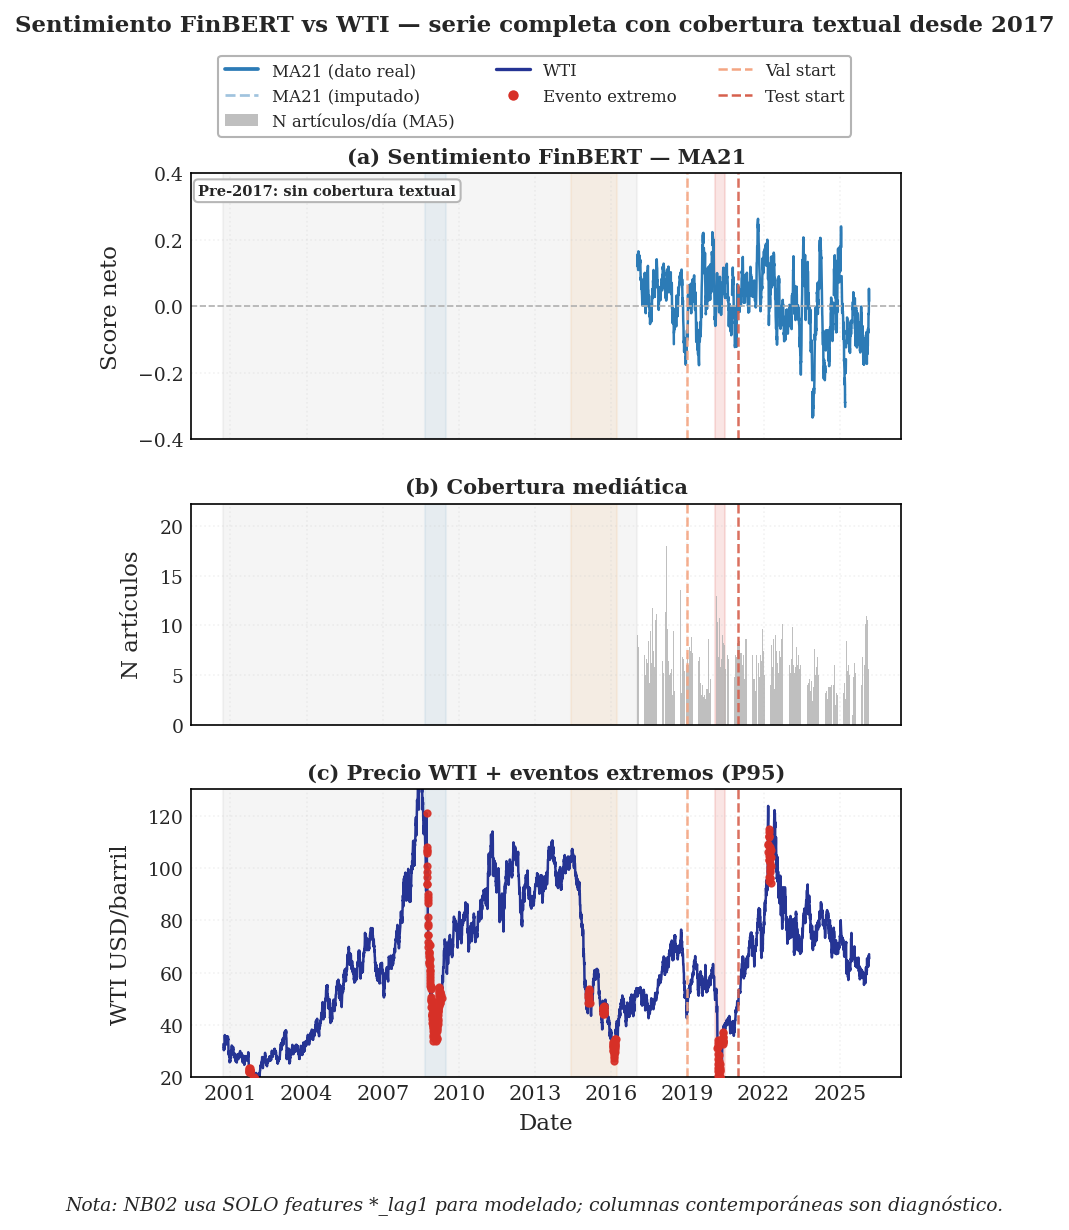

In [18]:
#  7.1 Serie temporal de sentimiento
fig, axes = plt.subplots(3, 1, figsize=fig_size('nb03_ts'), sharex=True,
                        gridspec_kw={'height_ratios': [1.2, 1, 1.3], 'hspace': 0.25})

SENT_COVERAGE_START = pd.Timestamp('2017-01-01')

CRISIS = [
    ('2008-09-01', '2009-06-30', COLOR_VAR),
    ('2014-06-01', '2016-03-31', COLORS_P[90]),
    ('2020-02-01', '2020-06-30', COLOR_EXTREMO),
]

SPLIT_LINES = [
    (pd.Timestamp(VAL_START),  SPLIT_COLORS['validation']),
    (pd.Timestamp(TEST_START), SPLIT_COLORS['test']),
]

def add_context(ax, show_pre2017=False):
    for s, e, col in CRISIS:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.12, color=col, zorder=0)
    ax.axvspan(daily.index.min(), SENT_COVERAGE_START, color=COLORS_SENT['neutral'], alpha=0.12, zorder=0)
    for x, col in SPLIT_LINES:
        ax.axvline(x, color=col, ls='--', lw=1.2, alpha=0.9)

    if show_pre2017:
        ax.text(0.01, 0.92, 'Pre-2017: sin cobertura textual',
                transform=ax.transAxes, fontsize=7, fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9,
                         edgecolor=COLORS_SENT['neutral'], pad=0.3))
    ax.set_facecolor('white')
    ax.grid(alpha=0.25, linestyle=':')

# (a) Sentimiento MA21
ma21 = daily['sentiment_score'].rolling(21, min_periods=5).mean()
y_real = ma21.where(daily['sentiment_flag'] == 1)
y_imp  = ma21.where(daily['sentiment_flag'] == 0)

axes[0].plot(daily.index, y_real, color=COLOR_VOL, lw=1.2)
axes[0].plot(daily.index, y_imp,  color=COLOR_VOL, lw=1.3, ls='--', alpha=0.6)
axes[0].axhline(0, color=COLORS_SENT['neutral'], ls='--', lw=0.8)
axes[0].set_ylim(-0.4, 0.4)
axes[0].set_ylabel('Score neto', fontsize=11, labelpad=8)
axes[0].set_title('(a) Sentimiento FinBERT — MA21', fontsize=10, fontweight='bold', pad=5)
add_context(axes[0], True)

# (b) Cobertura
n_art_plot = daily['n_articles'].fillna(0).rolling(5, min_periods=1).mean()
axes[1].bar(daily.index, n_art_plot, width=0.95, color=COLORS_SENT['neutral'], alpha=0.8)
axes[1].set_ylabel('N artículos', fontsize=11, labelpad=8)
axes[1].set_title('(b) Cobertura mediática', fontsize=10, fontweight='bold', pad=5)
add_context(axes[1], False)

# (c) WTI
axes[2].set_ylim(20, 130)
df_wti['wti_raw'].plot(ax=axes[2], color=COLOR_PRECIO, lw=1.2)
extremos = df_wti[df_wti['is_extreme_clean'] == 1]
axes[2].scatter(extremos.index, extremos['wti_raw'], color=COLOR_EXTREMO,
                s=10, zorder=10, linewidth=0.8, alpha=0.9)
axes[2].set_ylabel('WTI USD/barril', fontsize=11, labelpad=8)
axes[2].set_title('(c) Precio WTI + eventos extremos (P95)', fontsize=10, fontweight='bold', pad=5)
add_context(axes[2], False)

axes[2].xaxis.set_major_locator(mdates.YearLocator(3))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[2].get_xticklabels(), rotation=0, ha='center', fontsize=10)

legend_handles = [
    Line2D([0], [0], color=COLOR_VOL, lw=1.8, label='MA21 (dato real)'),
    Line2D([0], [0], color=COLOR_VOL, lw=1.3, ls='--', alpha=0.45, label='MA21 (imputado)'),
    Patch(facecolor=COLORS_SENT['neutral'], alpha=0.8, label='N artículos/día (MA5)'),
    Line2D([0], [0], color=COLOR_PRECIO, lw=1.6, label='WTI'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_EXTREMO,
           markeredgecolor='white', markersize=6, label='Evento extremo'),
    Line2D([0], [0], color=SPLIT_COLORS['validation'], ls='--', lw=1.2, label='Val start'),
    Line2D([0], [0], color=SPLIT_COLORS['test'], ls='--', lw=1.2, label='Test start'),
]

fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.975),
           ncol=3, frameon=True, framealpha=0.95, edgecolor=COLORS_SENT['neutral'],
           fontsize=8, columnspacing=2.5)

fig.suptitle('Sentimiento FinBERT vs WTI — serie completa con cobertura textual desde 2017',
             fontsize=11, fontweight='bold', y=1)
fig.text(0.5, 0.1,
         'Nota: NB02 usa SOLO features *_lag1 para modelado; columnas contemporáneas son diagnóstico.',
         ha='center', fontsize=9, style='italic')

plt.tight_layout(rect=[0, 0, 1, 0.98], h_pad=3.0)

save_fig(fig, 'fig01_sentiment_timeseries', output_path=FIG_PATH)
plt.show()
plt.close()

**Qué muestra**  
Esta figura presenta la serie completa del sentimiento agregado y la cobertura textual junto con el precio del WTI. El sombreado distingue el período sin cobertura textual y los principales cortes temporales del estudio.

**Cómo se construye**  
Se construye con promedios móviles del puntaje FinBERT, recuentos agregados de artículos y la serie histórica del WTI. Los eventos extremos y los límites de validación y test se superponen solo con fines descriptivos.

**Por qué se ve así**  
La parte previa a 2017 aparece atenuada porque no existe cobertura textual usable para este bloque exógeno. La continuidad visual permite contrastar el inicio tardío del insumo textual con la serie financiera completa.

**Por qué es importante**  
Esta figura aclara el soporte temporal real de las variables de sentimiento dentro del proyecto. También ayuda a justificar por qué el uso causal en NB02 se restringe a variables rezagadas.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/Fig_NB03/fig01_sentiment_timeseries_2017plus.png  [6.1"×8.9" @ 300dpi]


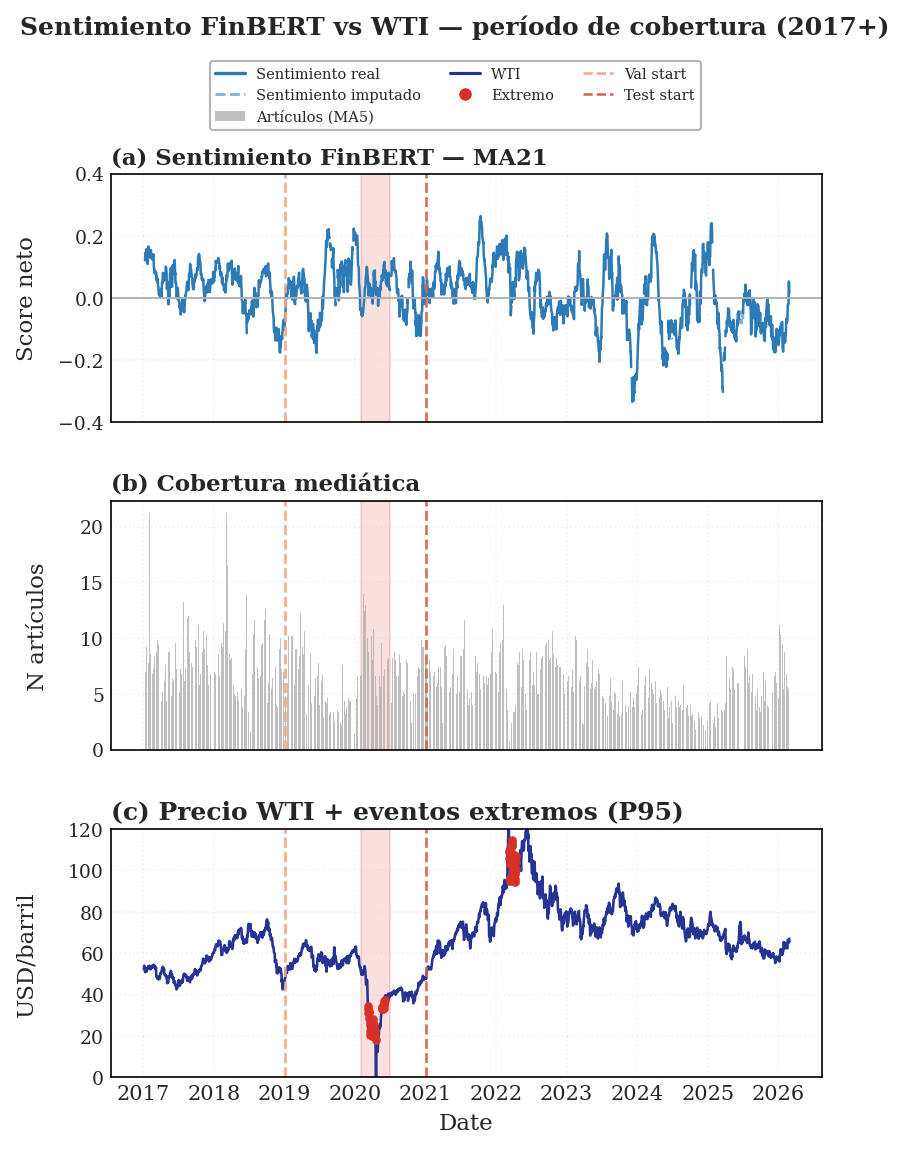

In [19]:
# 7.1 Serie temporal de sentimiento (solo 2017+) ─── IEEE A4
fig, axes = plt.subplots(3, 1,
                        figsize=fig_size('nb03_ts'),
                        sharex=True,
                        gridspec_kw={'height_ratios': [1, 1, 1], 'hspace': 0.32})

START_VIS = pd.Timestamp('2017-01-01')
daily_v = daily.loc[daily.index >= START_VIS].copy()
wti_v   = df_wti.loc[df_wti.index >= START_VIS].copy()

CRISIS = [('2020-02-01', '2020-06-30', COLOR_EXTREMO)]
SPLIT_LINES = [
    (pd.Timestamp(VAL_START), SPLIT_COLORS['validation']),
    (pd.Timestamp(TEST_START), SPLIT_COLORS['test'])
]

def add_context(ax):
    for s, e, col in CRISIS:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.15, color=col, zorder=0)
    for x, col in SPLIT_LINES:
        if x >= START_VIS:
            ax.axvline(x, color=col, ls='--', lw=1.3, alpha=0.9)
    ax.set_facecolor('white')
    ax.grid(alpha=0.25, linestyle=':')

# (a) Sentimiento MA21
ma21 = daily_v['sentiment_score'].rolling(21, min_periods=5).mean()
y_real = ma21.where(daily_v['sentiment_flag'] == 1)
y_imp  = ma21.where(daily_v['sentiment_flag'] == 0)

axes[0].plot(daily_v.index, y_real, color=COLOR_VOL, lw=1.2)
axes[0].plot(daily_v.index, y_imp, color=COLOR_VOL, lw=1.3, ls='--', alpha=0.6)
axes[0].axhline(0, color=COLORS_SENT['neutral'], ls='-', lw=0.9)
axes[0].set_ylim(-0.4, 0.4)
axes[0].set_ylabel('Score neto', fontsize=11, labelpad=10)
axes[0].set_title('(a) Sentimiento FinBERT — MA21', loc='left', fontsize=11, fontweight='bold', pad=5)
add_context(axes[0])

# (b) Cobertura
n_art_plot = daily_v['n_articles'].fillna(0).rolling(5, min_periods=1).mean()
axes[1].bar(daily_v.index, n_art_plot, width=0.95, color=COLORS_SENT['neutral'], alpha=0.8)
axes[1].set_ylabel('N artículos', fontsize=11, labelpad=15)
axes[1].set_title('(b) Cobertura mediática', loc='left', fontsize=11, fontweight='bold', pad=5)
add_context(axes[1])

# (c) WTI
axes[2].set_ylim(0, 120)
wti_v['wti_raw'].plot(ax=axes[2], color=COLOR_PRECIO, lw=1.25)
extremos_v = wti_v[wti_v['is_extreme_clean'] == 1]
axes[2].scatter(extremos_v.index, extremos_v['wti_raw'],
                color=COLOR_EXTREMO, s=10, zorder=10,
                linewidth=1.0, alpha=0.95)
axes[2].set_ylabel('USD/barril', fontsize=11, labelpad=15)
axes[2].set_title('(c) Precio WTI + eventos extremos (P95)', loc='left', fontsize=12, fontweight='bold', pad=5)
add_context(axes[2])

axes[2].xaxis.set_major_locator(mdates.YearLocator(1))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(axes[2].get_xticklabels(), rotation=0, ha='center', fontsize=10)

legend_handles = [
    Line2D([0], [0], color=COLOR_VOL, lw=1.6, label='Sentimiento real'),
    Line2D([0], [0], color=COLOR_VOL, ls='--', lw=1.3, alpha=0.6, label='Sentimiento imputado'),
    Patch(facecolor=COLORS_SENT['neutral'], alpha=0.8, label='Artículos (MA5)'),
    Line2D([0], [0], color=COLOR_PRECIO, lw=1.5, label='WTI'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=COLOR_EXTREMO,
           markeredgecolor='white', markersize=7, label='Extremo'),
    Line2D([0], [0], color=SPLIT_COLORS['validation'], ls='--', lw=1.2, label='Val start'),
    Line2D([0], [0], color=SPLIT_COLORS['test'], ls='--', lw=1.2, label='Test start'),
]

fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.97),
           ncol=3, frameon=True, framealpha=0.95, edgecolor=COLORS_SENT['neutral'],
           fontsize=7, columnspacing=2.0)

fig.suptitle('Sentimiento FinBERT vs WTI — período de cobertura (2017+)',
             fontsize=12, fontweight='bold', y=1)

plt.tight_layout(rect=[0, 0.8, 1, 1.1], h_pad=3.0)
save_fig(fig, 'fig01_sentiment_timeseries_2017plus', output_path=FIG_PATH)
plt.show()
plt.close()

**Qué muestra**  
Esta figura replantea la relación entre sentimiento, cobertura y WTI únicamente en el período con cobertura textual efectiva desde 2017. Su objetivo es facilitar una lectura más fina del tramo realmente utilizable para modelado.

**Cómo se construye**  
Se construye filtrando la misma información de la figura anterior al intervalo con cobertura textual disponible. Sobre ese tramo se mantienen los cortes de validación y test y la marcación de eventos extremos del WTI.

**Por qué se ve así**  
El recorte temporal elimina el tramo sin datos textuales y hace más visibles los cambios de cobertura y de régimen dentro del período reciente. Por eso el eje vertical y la composición lucen más compactos que en la serie completa.

**Por qué es importante**  
Esta vista permite evaluar el comportamiento del insumo textual exactamente en el período relevante para su uso empírico. También aporta una referencia visual directa para interpretar los features exportados a NB02.

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/Fig_NB03/fig02_sentiment_dist.png  [6.1"×3.8" @ 300dpi]


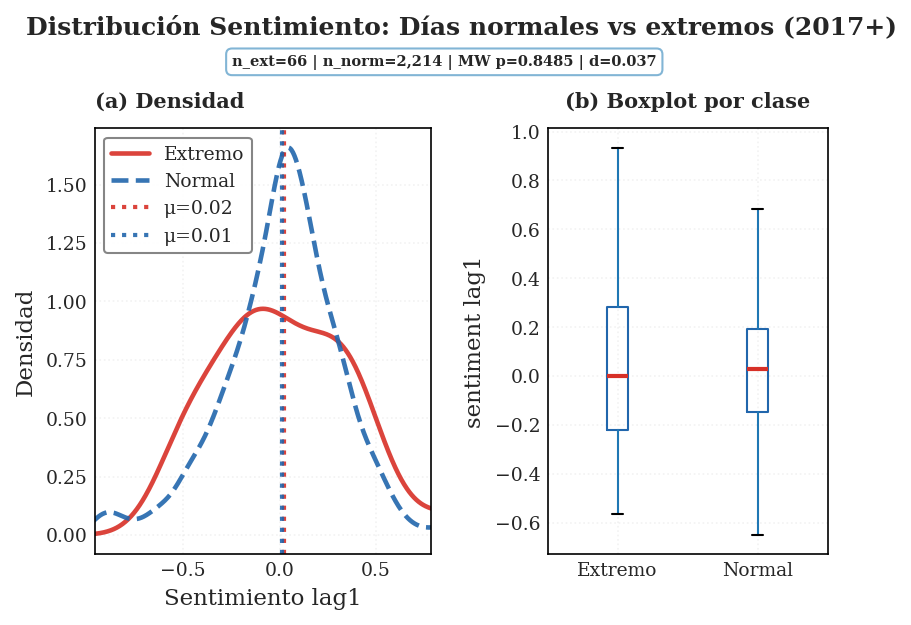

Días extremos con sentimiento: 66
Días normales con sentimiento: 2214
Media sentimiento — Extremo: 0.0246 | Normal: 0.0123
Mann-Whitney U: stat=72055.0, p=0.8485 (no significativoα=0.05)
Cohen's d: 0.037 (pequeño)


In [28]:
# Si el sentimiento es informativo, su distribución debe diferir
# entre días extremos y días normales.

df_analysis = df_wti[['is_extreme_clean']].join(
    daily[['sentiment_score_lag1', 'n_articles_lag1', 'sentiment_flag']], how='inner'
).dropna(subset=['is_extreme_clean', 'sentiment_score_lag1'])

# Foco en cobertura textual efectiva
df_analysis = df_analysis[df_analysis.index >= pd.Timestamp('2017-01-01')]

extremos_sent = df_analysis.loc[df_analysis['is_extreme_clean'] == 1, 'sentiment_score_lag1']
normales_sent = df_analysis.loc[df_analysis['is_extreme_clean'] == 0, 'sentiment_score_lag1']

n_ext = len(extremos_sent)
n_nor = len(normales_sent)

if (n_ext > 0 and n_nor > 0 and extremos_sent.nunique() > 1 and normales_sent.nunique() > 1):
    stat_mw, p_mw = stats.mannwhitneyu(extremos_sent, normales_sent, alternative='two-sided')
    pooled_std = np.sqrt((extremos_sent.std()**2 + normales_sent.std()**2) / 2)
    cohen_d = (extremos_sent.mean() - normales_sent.mean()) / pooled_std if pooled_std > 0 else np.nan
    stats_line = f'n_ext={n_ext:,} | n_norm={n_nor:,} | MW p={p_mw:.4f} | d={cohen_d:.3f}'
else:
    stat_mw, p_mw, cohen_d = np.nan, np.nan, np.nan
    stats_line = f'n_ext={n_ext:,} | n_norm={n_nor:,} | stats no disponibles'

fig, axes = plt.subplots(
    1, 2,
    figsize=fig_size('nb03_dist'),
    gridspec_kw={'width_ratios': [1.2, 1.0], 'wspace': 0.38}
)

# (a) KDE o hist fallback
if n_ext > 5 and n_nor > 5:
    extremos_sent.plot.kde(ax=axes[0], color=COLOR_EXTREMO, lw=2.2, label='Extremo', alpha=0.9)
    normales_sent.plot.kde(ax=axes[0], color=COLOR_NORMAL, lw=2.2, ls='--', label='Normal', alpha=0.9)
else:
    axes[0].hist(extremos_sent, bins=15, density=True, alpha=0.65, color=COLOR_EXTREMO, label='Extremo')
    axes[0].hist(normales_sent, bins=15, density=True, alpha=0.65, color=COLOR_NORMAL, label='Normal')

axes[0].axvline(extremos_sent.mean(), color=COLOR_EXTREMO, ls=':', lw=2.0, alpha=0.9, label=f'μ={extremos_sent.mean():.2f}')
axes[0].axvline(normales_sent.mean(), color=COLOR_NORMAL, ls=':', lw=2.0, alpha=0.9, label=f'μ={normales_sent.mean():.2f}')

# Limitar rango a percentiles para evitar colas vacías
if len(df_analysis) > 10:
    q1, q99 = df_analysis['sentiment_score_lag1'].quantile([0.01, 0.99])
    if np.isfinite(q1) and np.isfinite(q99) and q1 < q99:
        axes[0].set_xlim(q1 - 0.08, q99 + 0.08)

axes[0].set_title('(a) Densidad',loc='left', fontsize=10, fontweight='bold',pad=10)
axes[0].set_xlabel('Sentimiento lag1', fontsize=11)
axes[0].set_ylabel('Densidad', fontsize=11)
axes[0].legend(loc='upper left', fontsize=9, frameon=True, framealpha=0.95)
axes[0].grid(alpha=0.25, linestyle=':')
axes[0].set_facecolor('white')

# (b) Boxplot sin saturación de outliers
df_box = df_analysis.assign(clase=df_analysis['is_extreme_clean'].map({0: 'Normal', 1: 'Extremo'}))
df_box.boxplot(
    column='sentiment_score_lag1', by='clase', ax=axes[1],
    showfliers=False,
    boxprops=dict(color=COLOR_NORMAL),
    medianprops=dict(color=COLOR_EXTREMO, lw=2)
)
axes[1].set_title('(b) Boxplot por clase', fontsize=10, fontweight='bold',pad=10)
axes[1].set_xlabel('')
axes[1].set_ylabel('sentiment lag1', fontsize=11)
axes[1].set_facecolor('white')
axes[1].grid(alpha=0.25, linestyle=':')

# Título principal
fig.suptitle('Distribución Sentimiento: Días normales vs extremos (2017+)',
             fontsize=12, fontweight='bold', y=1.1)

# Stats elegantes
fig.text(0.25, 1.03, stats_line, fontsize=7, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9,
                  edgecolor=COLOR_VAR, pad=0.4),
         transform=fig.transFigure, va='top')

plt.tight_layout(rect=[0, 0.08, 1, 1.1])
save_fig(fig, 'fig02_sentiment_dist', output_path=FIG_PATH)
plt.show()
plt.close()

# Reporte en consola
print(f'Días extremos con sentimiento: {len(extremos_sent)}')
print(f'Días normales con sentimiento: {len(normales_sent)}')

if len(extremos_sent) < 5:
    print('⚠ Insuficientes días extremos con cobertura GDELT — '
          'posiblemente cobertura 2017+ no cubre suficientes eventos extremos de train.')

print(f'Media sentimiento — Extremo: {extremos_sent.mean():.4f} | '
      f'Normal: {normales_sent.mean():.4f}')

if p_mw != 1.0:
    print(f'Mann-Whitney U: stat={stat_mw:.1f}, p={p_mw:.4f} '
          f'({"*significativo" if p_mw < 0.05 else "no significativo"}α=0.05)')
    print(f"Cohen's d: {cohen_d:.3f} "
          f"({'grande' if abs(cohen_d)>0.8 else 'mediano' if abs(cohen_d)>0.5 else 'pequeño'})")


> Opción A — Resultado negativo documentado (recomendada): el pipeline híbrido funciona correctamente, la señal de sentimiento de GDELT no mejora la predicción. Conclusión: la hipótesis H1 (Híbrido > LSTM) no se confirma con esta fuente de datos. Esto refuerza el hallazgo H2-7 de NB02 (volumen tampoco aportaba).

> Opción B — Limitación de fuente: GDELT cubre bien 2017-2026 en volumen, pero los titulares de reuters.com y bloomberg.com pueden ser demasiado genéricos ("oil market", "crude oil price") para capturar el sentimiento específico que anticipa volatilidad extrema. Una fuente con análisis de analistas o earnings calls podría dar distinto resultado.

> Opción C — Período insuficiente en train: con solo ~497 días de sentimiento en train (2017-2018 de 4,584 totales), el modelo híbrido no puede aprender la relación sentimiento→volatilidad durante el entrenamiento. El test sería de un modelo que nunca vio la señal durante el aprendizaje

  [OK] /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/Fig_NB03/fig03_sentiment_corr.png  [6.1"×5.8" @ 300dpi]


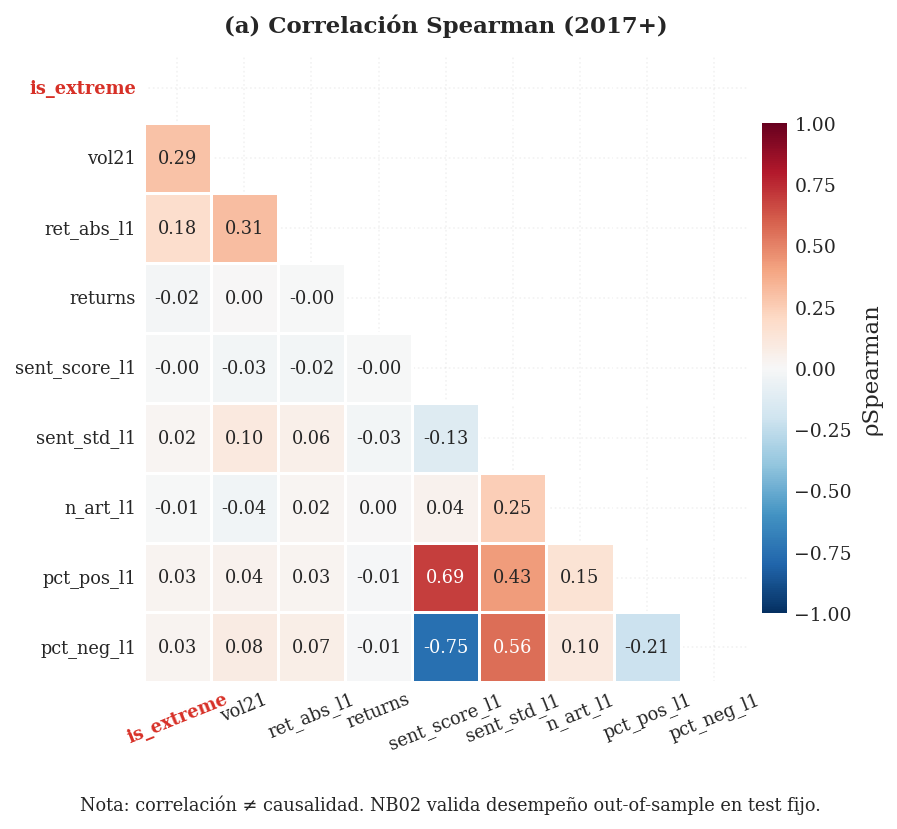


Correlación Spearman con is_extreme_clean (2017+):
  sentiment_score_lag1               : -0.0040
  sentiment_std_lag1                 : +0.0169
  n_articles_lag1                    : -0.0064
  pct_positive_lag1                  : +0.0289
  pct_negative_lag1                  : +0.0281


In [21]:
SENT_FEATURES_LAG1 = [
    'sentiment_score_lag1',
    'sentiment_std_lag1',
    'n_articles_lag1',
    'pct_positive_lag1',
    'pct_negative_lag1',
]

df_corr = df_wti[['vol21_clean', 'returns', 'ret_abs_lag1', 'is_extreme_clean']].join(
    daily[SENT_FEATURES_LAG1], how='inner'
).dropna()

df_corr = df_corr[df_corr.index >= pd.Timestamp('2017-01-01')]

ordered_cols = [
    'is_extreme_clean', 'vol21_clean', 'ret_abs_lag1', 'returns',
    'sentiment_score_lag1', 'sentiment_std_lag1', 'n_articles_lag1',
    'pct_positive_lag1', 'pct_negative_lag1'
]
ordered_cols = [c for c in ordered_cols if c in df_corr.columns]

corr_mat = df_corr[ordered_cols].corr(method='spearman')

# Nombres cortos para evitar solape
rename_map = {
    'is_extreme_clean':     'is_extreme',
    'vol21_clean':          'vol21',
    'ret_abs_lag1':         'ret_abs_l1',
    'sentiment_score_lag1': 'sent_score_l1',
    'sentiment_std_lag1':   'sent_std_l1',
    'n_articles_lag1':      'n_art_l1',
    'pct_positive_lag1':    'pct_pos_l1',
    'pct_negative_lag1':    'pct_neg_l1',
}
corr_plot = corr_mat.rename(index=rename_map, columns=rename_map)

fig, ax = plt.subplots(figsize=fig_size('nb03_corr'))

mask = np.zeros_like(corr_plot, dtype=bool)
mask[np.triu_indices_from(mask)] = True

sns.heatmap(
    corr_plot, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax,
    annot_kws={'size': 8.5},
    cbar_kws={'label': 'ρSpearman', 'shrink': 0.78, 'pad': 0.02}
)

ax.set_title('(a) Correlación Spearman (2017+)', fontsize=11, fontweight='bold')
ax.tick_params(axis='x', rotation=22, labelsize=8.5)
ax.tick_params(axis='y', rotation=0, labelsize=8.5)
ax.set_facecolor('white')

# resaltar target
for t in ax.get_xticklabels():
    if t.get_text() == 'is_extreme':
        t.set_color(COLOR_EXTREMO)
        t.set_fontweight('bold')
for t in ax.get_yticklabels():
    if t.get_text() == 'is_extreme':
        t.set_color(COLOR_EXTREMO)
        t.set_fontweight('bold')

fig.text(
    0.5, 0.01,
    'Nota: correlación ≠ causalidad. NB02 valida desempeño out-of-sample en test fijo.',
    ha='center', fontsize=8.5
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
save_fig(fig, 'fig03_sentiment_corr', output_path=FIG_PATH)
plt.show()
plt.close()

print('\nCorrelación Spearman con is_extreme_clean (2017+):')
for col in SENT_FEATURES_LAG1:
    if col in df_corr.columns:
        r = df_corr[col].corr(df_corr['is_extreme_clean'], method='spearman')
        print(f'  {col:<35}: {r:+.4f}')



## PARTE VIII — Exportación

> El CSV exportado contiene **dos versiones** de las features de sentimiento:
> - `sentiment_score` (contemporáneo) → solo para diagnóstico / EDA
> - `sentiment_score_lag1` (rezagado 1 día) → el que **usa el modelo en NB02**
>
> NB02 Parte V carga este CSV y filtra las columnas `*_lag1`.

In [22]:
EXPORT_COLS = [
    # Features contemporáneas (diagnóstico)
    'sentiment_score', 'sentiment_std', 'n_articles',
    'pct_positive', 'pct_negative', 'sentiment_flag',
    'sentiment_age_days', 'sentiment_low_coverage',
    'sentiment_score_lag1', 'sentiment_std_lag1',
    'n_articles_lag1', 'pct_positive_lag1', 'pct_negative_lag1',
]

df_export = daily[EXPORT_COLS].copy()
df_export.index.name = 'Date'

assert df_export.index.is_monotonic_increasing, 'Índice no ordenado temporalmente'
assert not df_export['sentiment_score_lag1'].iloc[1:].isna().all(), \
    'sentiment_score_lag1 todo NaN — revisar shift'

print(f'Shape final: {df_export.shape}')
print(f'Período: {df_export.index.min().date()} → {df_export.index.max().date()}')
print(f'\nNaN por columna lag1:')
print(df_export[[c for c in EXPORT_COLS if 'lag1' in c]].isna().sum())

df_export.head(3)


Shape final: (6385, 13)
Período: 2000-09-22 → 2026-02-27

NaN por columna lag1:
sentiment_score_lag1    4083
sentiment_std_lag1      4083
n_articles_lag1         4083
pct_positive_lag1       4083
pct_negative_lag1       4083
dtype: int64


,sentiment_score,sentiment_std,n_articles,pct_positive,pct_negative,sentiment_flag,sentiment_age_days,sentiment_low_coverage,sentiment_score_lag1,sentiment_std_lag1,n_articles_lag1,pct_positive_lag1,pct_negative_lag1
Date,,,,,,,,,,,,,
2000-09-22,NaN,NaN,NaN,NaN,NaN,0,999,1,NaN,NaN,NaN,NaN,NaN
2000-09-25,NaN,NaN,NaN,NaN,NaN,0,999,1,NaN,NaN,NaN,NaN,NaN
2000-09-26,NaN,NaN,NaN,NaN,NaN,0,999,1,NaN,NaN,NaN,NaN,NaN


In [23]:
#  8.2 Guardar CSV --
df_export.to_csv(OUTPUT_SENT, index=True)
print(f'CSV guardado: {OUTPUT_SENT}')
print(f'  Filas    : {len(df_export):,}')
print(f'  Columnas : {list(df_export.columns)}')

#  8.3 Actualizar config con metadata NB03 (opt-in)
if not WRITE_NB03:
    print('[SKIP] WRITE_NB03=False -> nb03 no se actualiza en el config.')
    print(f'       Config runtime intacto: {CONFIG_PATH}')
    print(f'       Espejo repo esperado : {CONFIG_REPO_MIRROR}')
else:
    if 'df_corr' not in dir() or df_corr is None or df_corr.empty:
        print('[SKIP] df_corr no disponible -> nb03 no se persiste para evitar metadata parcial.')
        print('       Ejecutar la celda 7.3 antes de escribir nb03 en config.')
    else:
        with open(CONFIG_PATH, 'r', encoding='utf-8') as f:
            config_out = json.load(f)

        _correlacion_target = {
            col: round(
                df_corr[col].corr(df_corr['is_extreme_clean'], method='spearman'), 4
            )
            for col in SENT_FEATURES_LAG1
            if col in df_corr.columns
        }

        config_out['nb03'] = {
            'fecha_ejecucion':     datetime.now().isoformat(),
            'fuente_titulares':    'GDELT Project (gdeltdoc)',
            'modelo_sentimiento':  'ProsusAI/finbert',
            'cobertura_texto_real_desde':  '2017-01-01',
            'pre_2017_datos_disponibles':  False,
            'pre_2017_tratamiento': (
                'NaN intencional - modelo hibrido entrenado solo en '
                'periodos con cobertura textual real (2017+)'
            ),
            'n_titulares_totales': len(df),
            'n_dias_reales':       n_real,
            'n_dias_imputados':    n_imputed,
            'cobertura_pct':       round(n_real / len(df_export) * 100, 2),
            'cobertura_split':     split_coverage,
            'cobertura_anual_pct': {
                str(y): round(v * 100, 2) for y, v in coverage_year.items()
            },
            'anios_baja_cobertura':        low_coverage_years,
            'umbral_baja_cobertura_pct':   int(LOW_COVERAGE_THRESHOLD * 100),
            'eia_role': (
                'auxiliary_structured_signal - inventarios semanales de crudo EEUU. '
                'No es sustituto de titulares textuales; es un proxy estructurado '
                'de sorpresa de mercado (inventory_surprise_zscore).'
            ),
            'coverage_usable_for_model': bool(SENTIMENT_USABLE_FOR_MODEL),
            'nb03_valid_for_inference':  bool(NB03_VALID_FOR_INFERENCE),
            'estado_modelo_hibrido': (
                'READY'
                if NB03_VALID_FOR_INFERENCE
                else 'SKIPPED_INSUFFICIENT_COVERAGE'
            ),
            'split_validation_vs_csv_ok': bool(
                '_split_validation_ok' in dir() and _split_validation_ok
            ),
            'leakage_checks_passed': bool(
                'LEAKAGE_CHECKS_PASSED' in dir() and LEAKAGE_CHECKS_PASSED
            ),
            'shift_aplicado':  'sentiment_score(t-1) -> features en t',
            'features_lag1':   [c for c in EXPORT_COLS if 'lag1' in c],
            'features_modelo': FEATURES_MODEL,
            'correlacion_target': _correlacion_target,
            'validacion_predictiva_lag1': {
                'r_contemporaneo':           round(r_contemp, 4),
                'r_lag1_target_t1':          round(r_lag1, 4),
                'bootstrap_spearman_mediana': (
                    None if np.isnan(boot_med) else round(boot_med, 4)
                ),
                'bootstrap_spearman_ic95': [
                    None if np.isnan(boot_lo) else round(boot_lo, 4),
                    None if np.isnan(boot_hi) else round(boot_hi, 4),
                ],
            },
            'advertencias': [
                'Usar SOLO columnas *_lag1 en NB02 - las contemporaneas son para diagnostico',
                'Dias sin cobertura GDELT imputados con ffill(limit=3) dentro de 2017+',
                'Pre-2017 queda NaN intencional - no usar para entrenar el hibrido',
                'Cobertura GDELT confiable desde 2017-01-01 (GDELT 2.0)',
            ],
        }

        assert config_out['nb03']['coverage_usable_for_model'] == bool(SENTIMENT_USABLE_FOR_MODEL), \
            "Inconsistencia: coverage_usable_for_model no coincide con SENTIMENT_USABLE_FOR_MODEL"
        assert config_out['nb03']['nb03_valid_for_inference'] == bool(NB03_VALID_FOR_INFERENCE), \
            "Inconsistencia: nb03_valid_for_inference no coincide con NB03_VALID_FOR_INFERENCE"
        assert 'sentiment_usable_for_model' not in config_out['nb03'], \
            "BUG: clave duplicada 'sentiment_usable_for_model' encontrada - revisar el dict"
        print('[OK] Consistencia de nb03 validada antes de escribir config')

        import shutil
        _tmp = CONFIG_PATH + '.tmp'
        try:
            with open(_tmp, 'w', encoding='utf-8') as f:
                json.dump(config_out, f, ensure_ascii=False, indent=2)
            shutil.move(_tmp, CONFIG_PATH)
            print('[OK] config_estudio_FINAL.json actualizado con nb03')
            print(f'[INFO] Espejo repo esperado: {CONFIG_REPO_MIRROR}')
        except Exception as e:
            if os.path.exists(_tmp):
                os.remove(_tmp)
            raise RuntimeError(f"Error escribiendo config: {e}")

        print(
            f"  Estado hibrido : {config_out['nb03']['estado_modelo_hibrido']}\n"
            f"  coverage_usable: {config_out['nb03']['coverage_usable_for_model']}\n"
            f"  nb03_valid     : {config_out['nb03']['nb03_valid_for_inference']}\n"
            f"  leakage_ok     : {config_out['nb03']['leakage_checks_passed']}\n"
            f"  split_val_ok   : {config_out['nb03']['split_validation_vs_csv_ok']}"
        )

CSV guardado: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/wti_sentiment_finbert.csv
  Filas    : 6,385
  Columnas : ['sentiment_score', 'sentiment_std', 'n_articles', 'pct_positive', 'pct_negative', 'sentiment_flag', 'sentiment_age_days', 'sentiment_low_coverage', 'sentiment_score_lag1', 'sentiment_std_lag1', 'n_articles_lag1', 'pct_positive_lag1', 'pct_negative_lag1']
[SKIP] WRITE_NB03=False -> nb03 no se actualiza en el config.
       Config runtime intacto: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/config_estudio_FINAL.json
       Espejo repo esperado : config/config_estudio_FINAL.json


In [24]:
print('NB03A — Última corrida válida registrada')
print('OUTPUT PRINCIPAL:')
print('  CSV de sentimiento exportado por la última corrida válida')
print('  Ver ruta canónica en config/docs (`data/sentiment/wti_sentiment_finbert.csv`)')
print()
print('LECTURA RAPIDA:')
print('  - Extension complementaria para NB02')
print('  - Consumir SOLO columnas *_lag1')
print('  - No redefine el benchmark canónico CPU')
print(f'Fecha registrada: {datetime.now().strftime("%Y-%m-%d %H:%M")}')

NB03A — Última corrida válida registrada
OUTPUT PRINCIPAL:
  CSV de sentimiento exportado por la última corrida válida
  Ver ruta canónica en config/docs (`data/sentiment/wti_sentiment_finbert.csv`)

LECTURA RAPIDA:
  - Extension complementaria para NB02
  - Consumir SOLO columnas *_lag1
  - No redefine el benchmark canónico CPU
Fecha registrada: 2026-03-25 22:09


In [25]:
if IN_COLAB:
    import re

    def _update_req_section(req_path, section_id, header_comment, packages):
        import subprocess, re, os
        result = subprocess.run(["pip", "freeze"], capture_output=True, text=True)
        lines_found = sorted(set([
            l for l in result.stdout.splitlines()
            if any(l.lower().startswith(pkg.lower()) for pkg in packages)
        ]))
        try:
            with open(req_path, encoding="utf-8") as _f:
                content = _f.read()
        except FileNotFoundError:
            content = (
                "# =====================================================================\n"
                "# requirements.txt -- Proyecto WTI: Prediccion de Volatilidad\n"
                "# Entorno: Python 3.10+ (Google Colab)\n"
                "# Creado: " + datetime.now().strftime("%Y-%m-%d") + "\n"
                "# =====================================================================\n"
                "#\n"
                "# pip install -r requirements.txt   (instala todo)\n"
                "#\n"
            )
        sec_start = "# -- " + section_id + ": " + header_comment
        sec_end   = "# -- [END " + section_id + "]"
        nueva = (
            "\n" + sec_start + " (actualizado " + datetime.now().strftime("%Y-%m-%d") + ") --\n"
            + "\n".join(lines_found)
            + "\n" + sec_end + "\n"
        )
        patron = re.compile(
            re.escape("# -- " + section_id + ":") + r".*?" + re.escape(sec_end) + r"\n",
            re.DOTALL
        )
        content = patron.sub(nueva, content) if patron.search(content) else content + nueva
        os.makedirs(os.path.dirname(req_path) or ".", exist_ok=True)
        with open(req_path, "w", encoding="utf-8") as _f:
            _f.write(content)
        print("  [OK] requirements.txt -- seccion " + section_id + ": " + str(len(lines_found)) + " paquetes")
        for l in lines_found:
            print("       " + l)
        return lines_found

    REQ_PATH = f"{BASE_PATH}/requirements.txt"
    _update_req_section(
        req_path      = REQ_PATH,
        section_id    = "NB03",
        header_comment= "Sentimiento FinBERT (NLP)",
        packages      = [
            "torch", "transformers", "gdeltdoc",
            "huggingface-hub", "tokenizers",
        ]
    )
    print(f"  requirements.txt: {REQ_PATH}")


  [OK] requirements.txt -- seccion NB03: 11 paquetes
       gdeltdoc==1.5.0
       tokenizers==0.22.2
       torch==2.10.0+cu128
       torchao==0.10.0
       torchaudio==2.10.0+cu128
       torchcodec==0.10.0+cu128
       torchdata==0.11.0
       torchsummary==1.5.1
       torchtune==0.6.1
       torchvision==0.25.0+cu128
       transformers==5.0.0
  requirements.txt: /content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/requirements.txt


In [26]:
# ── Análisis de sensibilidad — solo para diagnóstico
# Define splits alternativos SOLO para calcular correlaciones
# y explorar si la señal mejora con datos de cobertura real.
# NO se usa para entrenar el modelo híbrido comparativo con NB02.

SENT_COVERAGE_START = '2017-01-01'

splits_nb03_sensitivity = [
    ('train_sent',  '2017-01-01', '2018-12-31'),
    ('validation',  VAL_START,    VAL_END),       # ← mismo que NB02
    ('test',        TEST_START,   END_DATE),       # ← mismo que NB02
]

print("─── Correlación por split (solo período con cobertura real) ─")
print("NOTA: splits alternativos para diagnóstico — test fijo = NB02")
for name, s, e in splits_nb03_sensitivity:
    m = (df_wti_merged.index >= pd.Timestamp(s)) & \
        (df_wti_merged.index <= pd.Timestamp(e))
    sub = df_wti_merged.loc[m, ['sentiment_score_lag1', 'y_tp1']].dropna()
    if sub['y_tp1'].var() == 0 or len(sub) < 30:
        print(f"  {name:<14}: n/a (n={len(sub)}, eventos={int(sub['y_tp1'].sum())})")
        continue
    rr = sub['sentiment_score_lag1'].corr(sub['y_tp1'], method='spearman')
    print(f"  {name:<14}: {rr:+.4f}  (n={len(sub)}, "
          f"eventos={int(sub['y_tp1'].sum())})")
print()
print("Para comparación con NB02, usar SIEMPRE splits canónicos.")

─── Correlación por split (solo período con cobertura real) ─
NOTA: splits alternativos para diagnóstico — test fijo = NB02
  train_sent    : n/a (n=501, eventos=0)
  validation    : -0.0377  (n=483, eventos=39)
  test          : +0.0012  (n=1295, eventos=27)

Para comparación con NB02, usar SIEMPRE splits canónicos.


## Lectura de la última corrida válida conocida

- La cobertura textual real comienza en 2017 y se conserva `NaN` antes de ese punto para no fabricar señal fuera de soporte.
- La cobertura operativa en validation/test es alta, pero la señal predictiva observada es débil y debe interpretarse como una extensión complementaria del benchmark.
- El CSV `wti_sentiment_finbert.csv` y la sección `nb03` documentan la última salida válida conocida de este pipeline.
- Este bloque resume evidencia histórica del notebook; no debe leerse como garantía de ejecución actual ni como validación independiente del benchmark canónico.

In [27]:
# -- Resumen de Parámetros clave — generado dinámicamente --
# Nota: generado dinámicamente desde variables del notebook; no hardcodeado.
# Fuente contextual: config/config_estudio_FINAL.json (si se usa).
# Condicion: valores de correlacion solo se muestran si existe variable calculada.
from IPython.display import display, Markdown

def _get_any(*names, default=None):
    for name in names:
        if name in globals():
            value = globals()[name]
            if value is not None:
                return value
    return default

def _fmt_list(values, max_items=8):
    if not isinstance(values, (list, tuple)):
        return str(values)
    items = [f"`{x}`" for x in values[:max_items]]
    extra = f" ... (+{len(values) - max_items} mas)" if len(values) > max_items else ""
    return ", ".join(items) + extra

def _fmt_value(value):
    if value in (None, "", "None", "None -> None", "No disponible"):
        return "*No disponible en variables actuales*"
    if isinstance(value, float):
        return f"{value:.4f}"
    if isinstance(value, (list, tuple)):
        return _fmt_list(value)
    text = str(value)
    if "/" in text or text.endswith((".csv", ".json", ".ipynb")):
        return f"`{text}`"
    return text

_nb_file = "3A_WTI__Sentimiento_FinBERT.ipynb"
_nb_rol = "COMPLEMENTARIO - Sentimiento FinBERT"

# r Spearman: solo si existe como variable calculada en este notebook
_spearman_r = _get_any("spearman_r", "r_spearman", "spearman_lag1")
if isinstance(_spearman_r, (int, float)):
    _spearman_str = f"{_spearman_r:.4f}"
else:
    _spearman_str = "ver celda de hallazgo central (sin variable calculada disponible)"

_sent_cols = _get_any(
    "SENT_FEATURES_LAG1",
    "FEATURES_LAG1",
    "features_lag1",
    "sentiment_cols",
    "EXPORT_COLS",
    default=[]
)

_resumen = {
    "Notebook": f"{_nb_file} | Rol: {_nb_rol}",
    "Clasificacion": _nb_rol,
    "Fuente sentimiento": (
        _get_any("GDELT_URL", "gdelt_source", "SENTIMENT_SOURCE")
        or "GDELT + FinBERT (variable no encontrada)"
    ),
    "Cobertura textual desde": _get_any("SENT_COVERAGE_START", default="2017-01-01"),
    "OUTPUT_SENT (CSV)": _get_any("OUTPUT_SENT", "SENTIMENT_CSV", "sentiment_output_path"),
    "Columnas *_lag1 export": _sent_cols,
    "r Spearman lag-1": _spearman_str,
    "Seed": _get_any("RANDOM_SEED", "SEED", "seed"),
    "Train hasta": _get_any("TRAIN_END", "train_end_date"),
    "Val": f"{_get_any('VAL_START', 'val_start_date')} -> {_get_any('VAL_END', 'val_end_date')}",
    "Test desde": _get_any("TEST_START", "test_start_date"),
    "RUN_MODE": _get_any("RUN_MODE"),
    "Nota de integracion": "Consumir SOLO columnas *_lag1. No redefine el benchmark canonico CPU.",
}

_lines = [
    "---",
    "### Resumen de Parametros clave generado dinamicamente",
    "",
    "> Generado desde variables del notebook. No hardcodeado.",
    "> Fuente contextual: `config/config_estudio_FINAL.json`.",
    "> Valores de correlacion solo se incluyen si existe variable calculada en esta sesion.",
    "",
]

for k, v in _resumen.items():
    _lines.append(f"- **{k}:** {_fmt_value(v)}")

_lines += ["", "---"]

display(Markdown("\n".join(_lines)))

---
### Resumen de Parametros clave generado dinamicamente

> Generado desde variables del notebook. No hardcodeado.
> Fuente contextual: `config/config_estudio_FINAL.json`.
> Valores de correlacion solo se incluyen si existe variable calculada en esta sesion.

- **Notebook:** 3A_WTI__Sentimiento_FinBERT.ipynb | Rol: COMPLEMENTARIO - Sentimiento FinBERT
- **Clasificacion:** COMPLEMENTARIO - Sentimiento FinBERT
- **Fuente sentimiento:** GDELT + FinBERT (variable no encontrada)
- **Cobertura textual desde:** 2017-01-01
- **OUTPUT_SENT (CSV):** `/content/drive/My Drive/2410VDSO Trabajo de Grado/Modelos/NB03_FinBERT/wti_sentiment_finbert.csv`
- **Columnas *_lag1 export:** `sentiment_score_lag1`, `sentiment_std_lag1`, `n_articles_lag1`, `pct_positive_lag1`, `pct_negative_lag1`
- **r Spearman lag-1:** ver celda de hallazgo central (sin variable calculada disponible)
- **Seed:** 42
- **Train hasta:** 2018-12-31
- **Val:** 2019-01-02 -> 2020-12-31
- **Test desde:** 2021-01-02
- **RUN_MODE:** *No disponible en variables actuales*
- **Nota de integracion:** Consumir SOLO columnas *_lag1. No redefine el benchmark canonico CPU.

---